# Q1. Do some genres earn more than others at the same budget?

This notebook asks whether films of some genres return more on their budget than films of the same budget in
other genres. The return is ln(gross / budget): 0 means the gross equalled the budget, 0.69 means it doubled it.
Gross over budget isn't profit, because marketing isn't in the budget and cinemas keep part of the gross.

It reads the saved outputs of `python -m analysis.genre.q1_genre` (the main test) and
`python -m analysis.genre.q1_checks` (five follow-up checks) and needs no raw data. The method and its limits are
in [`analysis/genre/README.md`](../analysis/genre/README.md) and [`CHECKS.md`](../analysis/genre/CHECKS.md).

Sections:
1. The films and the settings
2. The main test
3. Does the null matter?
4. A second method: regression
5. On the common set
6. Check 1: a smooth budget curve instead of bins
7. Check 2: genre x budget tier
8. Check 3: without each genre's biggest hits
9. Check 5: hit share and the share below budget
10. A second source: TMDB genres and money
11. Content rating and Horror subgenres
12. Finer categories: Wikidata genres and a keyword network
13. Before release: genre specialists and script typicality
Exploratory part:
14. Check 4: matched pairs
15. The genre network
16. Do films made by the same people share genre?
17. Other ways to say what genre a film is
18. Inside Horror: which plot words go with beating the budget
19. Inside Horror, in the screenplays
20. The genre distribution through the same analyses
21. Fixing the genre distribution's weaknesses
22. Summary

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

REPO = Path.cwd().resolve().parent   # notebooks -> repo root
SRC = REPO / "analysis" / "genre" / "outputs"
CHK = SRC / "checks"
S = json.loads((SRC / "summary.json").read_text())
sh = pd.read_csv(SRC / "genre_shuffle.csv")
ols = pd.read_csv(SRC / "genre_ols.csv")
overlap = pd.read_csv(SRC / "overlap.csv")
smooth = pd.read_csv(CHK / "smooth.csv")
tiers = pd.read_csv(CHK / "tiers.csv")
trim = pd.read_csv(CHK / "trim.csv")
tops = pd.read_csv(CHK / "top_films.csv")
matched = pd.read_csv(CHK / "matched.csv")
shares = pd.read_csv(CHK / "shares.csv")
EXP = REPO / "analysis" / "genre" / "exploratory" / "outputs"   # weak evidence, not used for claims
BR = SRC / "before_release"
NET, SHR, WRD = EXP / "network", EXP / "shares", EXP / "words"
SN = json.loads((NET / "summary.json").read_text())
pairs = pd.read_csv(NET / "genre_pairs.csv")
families = pd.read_csv(NET / "genre_families.csv")
assort = pd.read_csv(NET / "film_assortativity.csv")
SS = json.loads((SHR / "summary.json").read_text())
share_tests = pd.read_csv(SHR / "share_tests.csv")
agreement = pd.read_csv(SHR / "agreement.csv")
cv = pd.read_csv(SHR / "cv_r2.csv")
clusters = pd.read_csv(SHR / "plot_clusters.csv")
SW = json.loads((WRD / "horror_summary.json").read_text())
wtop = pd.read_csv(WRD / "horror_top.csv")
wlists = pd.read_csv(WRD / "horror_list_null.csv")
from IPython.display import Image, display
SF = EXP / "share_followups"
SFS = json.loads((SF / "summary.json").read_text())
FX = EXP / "share_fixes"
FXS = json.loads((FX / "summary.json").read_text())
BRS = json.loads((BR / "summary.json").read_text())
CAT = SRC / "categories"
CATS = json.loads((CAT / "summary.json").read_text())
TM = SRC / "tmdb"
TMS = json.loads((TM / "summary.json").read_text())
HSC = EXP / "horror_scripts"
HSS = json.loads((HSC / "summary.json").read_text())

BLUE, RED, GREY, INK = "#2f6db5", "#c0504d", "#b8b8b8", "#222"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format

def view(set_="usable_money", outcome="ln_ratio", null="budget"):
    return sh[(sh["set"] == set_) & (sh["outcome"] == outcome) & (sh["null"] == null)].set_index("genre")

main = view()
SEVEN = main.index[main["p_holm"] < .05].intersection(
    view(null="budget_era").index[view(null="budget_era")["p_holm"] < .05]).intersection(
    view(null="none").index[view(null="none")["p_holm"] < .05]).intersection(
    view(outcome="rank").index[view(outcome="rank")["p_holm"] < .05]).tolist()
def colour(r):
    return GREY if r["p_holm"] >= .05 else (BLUE if r["excess"] > 0 else RED)

## 1. The films and the settings

The films are every film with `usable_money` in the shared analysis set (budget and gross both in US dollars,
the shared clean rule from `analysis/clean_rule.py`, no flagged figures). A film counts in every IMDb genre it
has, and genres with fewer than the minimum number of films are left out. The settings were fixed in the script
before any genre result was looked at.

In [2]:
for s, v in S["sets"].items():
    print(f"{s}: {v['films']:,} films, {len(v['genres_kept'])} genres with at least {S['min_films']} films, "
          f"{v['mean_genres_per_film']} genres per film, mean ln(gross/budget) {v['all_film_mean_ln_ratio']:.3f}")
print(f"shuffles: {S['perms']:,}, budget deciles: {S['budget_bins']}, seed {S['seed']}")

usable_money: 6,346 films, 18 genres with at least 100 films, 2.61 genres per film, mean ln(gross/budget) 0.573
in_common_set: 1,598 films, 12 genres with at least 100 films, 2.45 genres per film, mean ln(gross/budget) 1.005
shuffles: 10,000, budget deciles: 10, seed 2805


Genres overlap a lot, so the tests below aren't independent. The largest overlaps, as the share of the first
genre's films that also carry the second:

In [3]:
overlap.sort_values("share_of_a", ascending=False).head(8).reset_index(drop=True)

,genre_a,genre_b,films_both,share_of_a
0,History,Drama,183,0.958
1,Biography,Drama,422,0.904
2,Animation,Adventure,317,0.885
3,War,Drama,84,0.832
4,Music,Drama,152,0.710
5,Romance,Drama,690,0.689
6,Sport,Drama,114,0.667
7,Family,Comedy,229,0.622


## 2. The main test

For each genre, the mean return of its films is compared with shuffles in which returns are swapped only
between films in the same decile of ln(budget). The genre tags stay where they are. So the band shows what the
genre's films would return on average if genre didn't matter, given their budgets. A bar outside the band (Holm
p < .05 over the genres) means the genre returns more, or less, than its budgets predict.

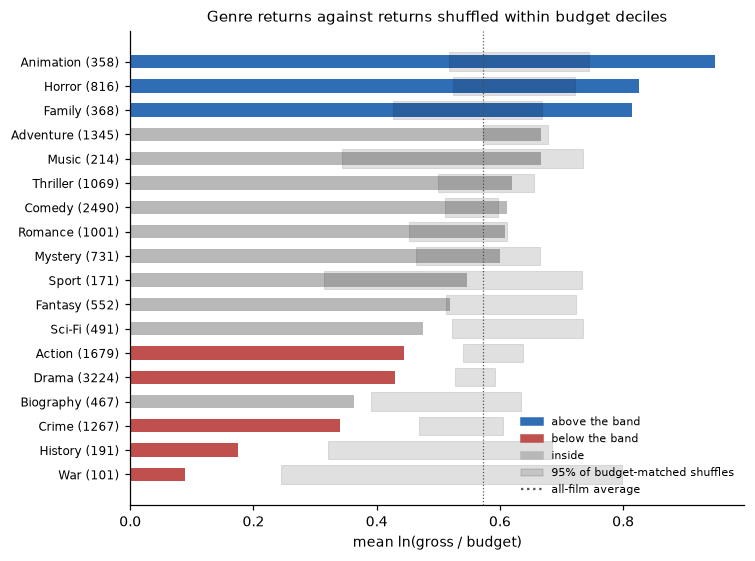

In [4]:
d = main.sort_values("mean")
fig, ax = plt.subplots(figsize=(7.2, 5.6))
yy = np.arange(len(d))
ax.barh(yy, d["mean"], color=[colour(r) for _, r in d.iterrows()], height=.55, zorder=2)
for k, (_, r) in enumerate(d.iterrows()):
    ax.add_patch(plt.Rectangle((r["null_lo95"], k - .38), r["null_hi95"] - r["null_lo95"], .76,
                               facecolor="#000", alpha=.12, edgecolor=INK, lw=.7, zorder=3))
overall = S["sets"]["usable_money"]["all_film_mean_ln_ratio"]
ax.axvline(overall, color="#555", ls=":", lw=.8)
ax.set_yticks(yy, [f"{g} ({n})" for g, n in zip(d.index, d["n_films"])], fontsize=8)
ax.set_xlabel("mean ln(gross / budget)")
ax.legend(handles=[Patch(color=BLUE, label="above the band"), Patch(color=RED, label="below the band"),
                   Patch(color=GREY, label="inside"), Patch(facecolor="#000", alpha=.12, edgecolor=INK, label="95% of budget-matched shuffles"),
                   Line2D([], [], color="#555", ls=":", label="all-film average")], fontsize=7, loc="lower right", frameon=False)
ax.set_title("Genre returns against returns shuffled within budget deciles", fontsize=10)
plt.show()

In [5]:
t = main[["n_films", "mean", "null_mean", "excess", "z", "p_holm"]].copy()
t["times"] = np.exp(t["excess"])
t.rename(columns={"null_mean": "expected", "times": "x gross/budget"}).sort_values("excess", ascending=False)

,n_films,mean,expected,excess,z,p_holm,x gross/budget
genre,,,,,,,
Animation,358,0.949,0.633,0.316,5.450,0.002,1.371
Family,368,0.814,0.548,0.266,4.320,0.002,1.305
Horror,816,0.826,0.623,0.203,4.040,0.003,1.225
Music,214,0.666,0.542,0.124,1.250,0.844,1.132
Romance,1001,0.608,0.531,0.076,1.870,0.419,1.079
Comedy,2490,0.611,0.554,0.058,2.670,0.059,1.059
Adventure,1345,0.667,0.625,0.042,1.560,0.585,1.043
Thriller,1069,0.619,0.579,0.041,1.020,0.933,1.042
Mystery,731,0.600,0.566,0.034,0.670,1.000,1.035


`excess` is the genre's mean minus what its budgets predict, and `x gross/budget` turns it into a factor: a
factor above 1 means the genre's films return that much more gross per dollar of budget than films of the same
budgets (1.2 would be 20 % more).

## 3. Does the null matter?

The same test with three other nulls: no budget matching at all, matching on budget decile x era (returns fall a
lot by decade), and the budget-matched shuffle on the percentile rank of the return, where each film counts once
however extreme it is. The genres that pass all four are the result we report.

In [6]:
rows = {}
for null, outcome, name in [("none", "ln_ratio", "no matching"), ("budget", "ln_ratio", "budget"),
                            ("budget_era", "ln_ratio", "budget x era"), ("budget_fine", "ln_ratio", "50 budget bins"),
                            ("budget", "rank", "ranks")]:
    v = view(outcome=outcome, null=null)
    rows[(name, "excess")] = v["excess"]
    rows[(name, "p_holm")] = v["p_holm"]
pd.DataFrame(rows).sort_values(("budget", "excess"), ascending=False)

no matching        budget        budget x era        50 budget bins  \
               excess p_holm excess p_holm       excess p_holm         excess   
genre                                                                           
Animation       0.376  0.002  0.316  0.002        0.305  0.002          0.310   
Family          0.242  0.010  0.266  0.002        0.223  0.003          0.264   
Horror          0.253  0.002  0.203  0.003        0.230  0.002          0.195   
Music           0.093  1.000  0.124  0.844        0.097  0.933          0.133   
Romance         0.035  1.000  0.076  0.419        0.101  0.113          0.079   
Comedy          0.038  0.648  0.058  0.059        0.048  0.133          0.058   
Adventure       0.094  0.060  0.042  0.585        0.007  1.000          0.036   
Thriller        0.046  1.000  0.041  0.933        0.064  0.519          0.052   
Mystery         0.028  1.000  0.034  1.000        0.093  0.382          0.023   
Sport          -0.026  1.000  0.022  1.000       -0.051  1.000         -0.003   
Fantasy        -0.054  1.000 -0.100  0.419       -0.129  0.113         -0.101   
Drama          -0.143  0.002 -0.130  0.002       -0.105  0.002         -0.125   
Action         -0.128  0.002 -0.145  0.002       -0.158  0.002         -0.141   
Biography      -0.210  0.010 -0.150  0.110       -0.097  0.519         -0.133   
Sci-Fi         -0.097  0.764 -0.154  0.059       -0.181  0.010         -0.170   
Crime          -0.232  0.002 -0.197  0.002       -0.211  0.002         -0.186   
History        -0.399  0.002 -0.330  0.007       -0.298  0.021         -0.315   
War            -0.483  0.010 -0.439  0.029       -0.519  0.003         -0.405   

                  ranks         
          p_holm excess p_holm  
genre                           
Animation  0.002  0.081  0.002  
Family     0.002  0.049  0.003  
Horror     0.004  0.045  0.002  
Music      0.864  0.019  0.713  
Romance    0.356  0.014  0.542  
Comedy     0.054  0.013  0.037  
Adventure  0.864  0.017  0.027  
Thriller   0.864  0.010  0.711  
Mystery    1.000  0.006  0.713  
Sport      1.000 -0.029  0.711  
Fantasy    0.356 -0.021  0.385  
Drama      0.002 -0.030  0.002  
Action     0.002 -0.024  0.002  
Biography  0.234 -0.046  0.002  
Sci-Fi     0.022 -0.019  0.542  
Crime      0.002 -0.048  0.002  
History    0.010 -0.083  0.002  
War        0.026 -0.065  0.167

In [7]:
print("Pass all four (no matching, budget, budget x era, ranks):", ", ".join(SEVEN))
raw, matched_b = view(null="none")["excess"], main["excess"]
same = (np.sign(raw) == np.sign(matched_b.reindex(raw.index))).sum()
print(f"Same sign with and without budget matching: {same} of {len(raw)} genres")
print(f"Horror: {raw['Horror']:+.3f} without matching, {matched_b['Horror']:+.3f} with budget deciles, "
      f"{view(null='budget_fine').loc['Horror', 'excess']:+.3f} with 50 budget bins")

Pass all four (no matching, budget, budget x era, ranks): Action, Animation, Crime, Drama, Family, History, Horror
Same sign with and without budget matching: 17 of 18 genres
Horror: +0.253 without matching, +0.203 with budget deciles, +0.195 with 50 budget bins


Budget matching changes little. The genres that win aren't winning just because they're cheap. (The 50-bin
shuffle was added after the main results, when the lowest budget decile turned out to be very wide.)

## 4. A second method: regression

An OLS of ln(gross / budget) on all genres at once (multi-hot), budget decile and era, with HC3 errors. Its genre
coefficients hold the film's other genres fixed, so they answer a slightly different question. Almost every film
has at least one of the kept genres, so the raw coefficients sit against a near-empty reference; the centred
coefficient (minus the mean over genres) is the one to compare.

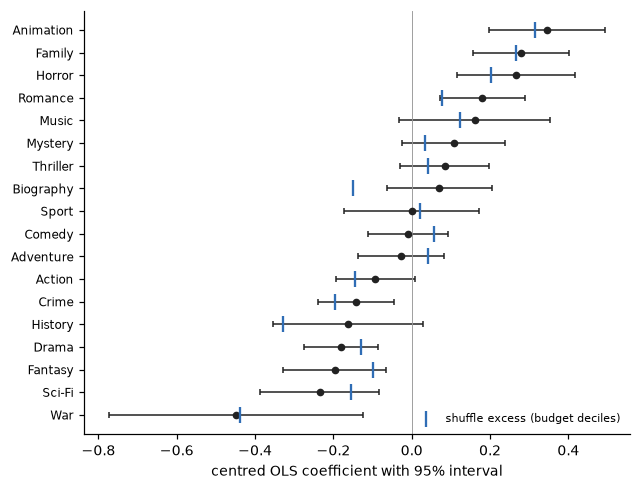

usable_money: R2 budget + era 0.063 -> with genre 0.096 (adds 0.032, adjusted 0.030); Spearman of OLS vs shuffle excess 0.93
in_common_set: R2 budget + era 0.129 -> with genre 0.155 (adds 0.026, adjusted 0.020); Spearman of OLS vs shuffle excess 0.74


In [8]:
o = ols[ols["set"] == "usable_money"].set_index("genre").sort_values("coef_centred")
fig, ax = plt.subplots(figsize=(6.4, 5))
yy = np.arange(len(o))
ax.errorbar(o["coef_centred"], yy, xerr=[o["coef_centred"] - o["ci95_lo_centred"], o["ci95_hi_centred"] - o["coef_centred"]],
            fmt="o", color=INK, ms=4, lw=1, capsize=2)
ax.scatter(main["excess"].reindex(o.index), yy, marker="|", s=120, color=BLUE, zorder=3, label="shuffle excess (budget deciles)")
ax.axvline(0, color="#999", lw=.6)
ax.set_yticks(yy, o.index, fontsize=8)
ax.set_xlabel("centred OLS coefficient with 95% interval")
ax.legend(fontsize=7, frameon=False, loc="lower right")
plt.show()
for s, v in S["sets"].items():
    print(f"{s}: R2 budget + era {v['r2_budget_era']:.3f} -> with genre {v['r2_budget_era_genre']:.3f} "
          f"(adds {v['r2_added_by_genre']:.3f}, adjusted {v['adj_r2_added_by_genre']:.3f}); "
          f"Spearman of OLS vs shuffle excess {v['spearman_ols_vs_shuffle_excess']:.2f}")

The regression ranks the genres almost as the shuffle does. Genre adds only a small part of the variance on
top of budget and era: it's a real but small effect.

## 5. On the common set

The common set is the films that have usable money and a MovieSum screenplay, the set on which Q1, Q2 and Q3 are
compared head to head. It has fewer genres with enough films (no Animation, no Family).

In [9]:
rows = {}
for null, name in [("none", "no matching"), ("budget", "budget"), ("budget_era", "budget x era"), ("budget_fine", "50 budget bins")]:
    v = view("in_common_set", null=null)
    rows[(name, "excess")] = v["excess"]
    rows[(name, "p_holm")] = v["p_holm"]
c = pd.DataFrame(rows)
c.insert(0, ("", "n_films"), view("in_common_set")["n_films"])
c.sort_values(("budget", "excess"), ascending=False)

no matching        budget        budget x era         \
          n_films      excess p_holm excess p_holm       excess p_holm   
genre                                                                    
Horror        200       0.260  0.013  0.174  0.278        0.179  0.147   
Adventure     338       0.107  0.385  0.132  0.018        0.054  0.832   
Romance       228       0.096  1.000  0.105  0.879        0.129  0.431   
Thriller      297       0.056  1.000  0.034  1.000        0.052  1.000   
Mystery       198       0.043  1.000  0.027  1.000        0.118  0.753   
Fantasy       146      -0.013  1.000  0.003  1.000       -0.019  1.000   
Comedy        541      -0.028  1.000 -0.024  1.000       -0.028  1.000   
Sci-Fi        163      -0.084  1.000 -0.068  1.000       -0.104  0.753   
Action        429      -0.131  0.070 -0.076  0.398       -0.123  0.004   
Drama         882      -0.080  0.025 -0.087  0.005       -0.055  0.147   
Biography     155      -0.208  0.137 -0.151  0.558       -0.108  0.832   
Crime         338      -0.256  0.001 -0.200  0.002       -0.169  0.010   

          50 budget bins         
                  excess p_holm  
genre                            
Horror             0.173  0.218  
Adventure          0.112  0.080  
Romance            0.111  0.667  
Thriller           0.031  1.000  
Mystery            0.009  1.000  
Fantasy           -0.008  1.000  
Comedy            -0.008  1.000  
Sci-Fi            -0.060  1.000  
Action            -0.083  0.218  
Drama             -0.084  0.009  
Biography         -0.129  0.713  
Crime             -0.206  0.002

## 6. Check 1: a smooth budget curve instead of bins

ln(gross / budget) minus a natural cubic spline in ln(budget) plus era; the genre means of that leftover against
a plain shuffle of it. No bin edges to choose, so this is the cleanest answer to "are the deciles too coarse?".

In [10]:
sm = smooth.set_index("genre")
pd.DataFrame({"main excess": main["excess"], "main p_holm": main["p_holm"],
              "smooth excess": sm["excess"], "smooth p_holm": sm["p_holm"]}).sort_values("main excess", ascending=False)

,main excess,main p_holm,smooth excess,smooth p_holm
genre,,,,
Animation,0.316,0.002,0.325,0.002
Family,0.266,0.002,0.236,0.005
Horror,0.203,0.003,0.226,0.002
Music,0.124,0.844,0.138,0.740
Romance,0.076,0.419,0.108,0.048
Comedy,0.058,0.059,0.059,0.047
Adventure,0.042,0.585,-0.009,1.000
Thriller,0.041,0.933,0.058,0.740
Mystery,0.034,1.000,0.066,0.740


## 7. Check 2: genre x budget tier

Four fixed budget tiers. Inside each, every genre against a shuffle within budget deciles among that tier's
films. Cells with too few films are grey; * marks Holm p < .05 over all filled cells. This shows *where* on the
budget scale genre matters.

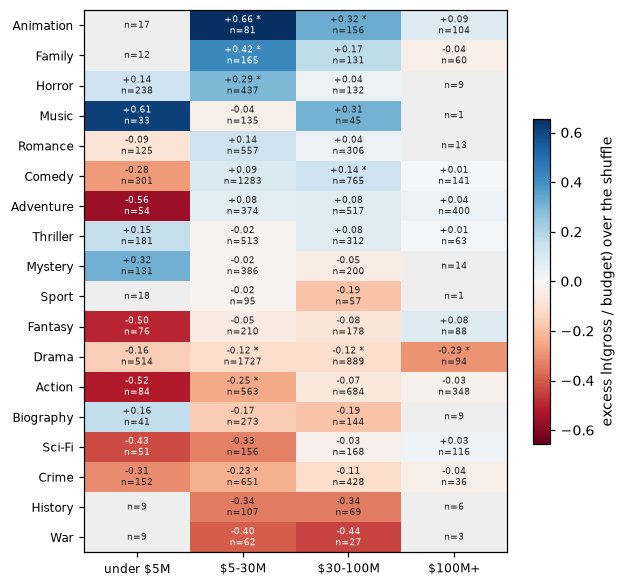

In [11]:
names = ["under $5M", "$5-30M", "$30-100M", "$100M+"]
order = main.sort_values("excess", ascending=False).index
E = tiers.pivot(index="genre", columns="tier", values="excess").reindex(index=order, columns=names)
P = tiers.pivot(index="genre", columns="tier", values="p_holm").reindex(index=order, columns=names)
N = tiers.pivot(index="genre", columns="tier", values="n_films").reindex(index=order, columns=names)
lim = np.nanmax(np.abs(E.to_numpy()))
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad("#eeeeee")
fig, ax = plt.subplots(figsize=(6.2, 6.4))
im = ax.imshow(np.ma.masked_invalid(E.to_numpy()), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
for i in range(len(order)):
    for k in range(len(names)):
        e, p, n = E.iat[i, k], P.iat[i, k], N.iat[i, k]
        txt = f"n={int(n)}" if np.isnan(e) else f"{e:+.2f}{' *' if p < .05 else ''}\nn={int(n)}"
        ax.text(k, i, txt, ha="center", va="center", fontsize=6,
                color=INK if np.isnan(e) or abs(e) < .6 * lim else "white")
ax.set_xticks(range(len(names)), names, fontsize=8)
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.spines[:].set_visible(True)
fig.colorbar(im, ax=ax, shrink=.6, label="excess ln(gross / budget) over the shuffle")
plt.show()

In [12]:
f = tiers[tiers["excess"].notna()]
print(f"{len(f)} filled cells, {(f['p_holm'] < .05).sum()} pass:")
for _, r in f[f["p_holm"] < .05].sort_values(["tier", "excess"]).iterrows():
    print(f"  {r['tier']:>9}  {r['genre']:<10} {r['excess']:+.2f}  ({int(r['n_films'])} films, Holm p {r['p_holm']:.3f})")

59 filled cells, 10 pass:
     $100M+  Drama      -0.29  (94 films, Holm p 0.015)
   $30-100M  Drama      -0.12  (889 films, Holm p 0.006)
   $30-100M  Comedy     +0.14  (765 films, Holm p 0.006)
   $30-100M  Animation  +0.32  (156 films, Holm p 0.020)
     $5-30M  Action     -0.25  (563 films, Holm p 0.006)
     $5-30M  Crime      -0.23  (651 films, Holm p 0.006)
     $5-30M  Drama      -0.12  (1727 films, Holm p 0.006)
     $5-30M  Horror     +0.29  (437 films, Holm p 0.006)
     $5-30M  Family     +0.42  (165 films, Holm p 0.010)
     $5-30M  Animation  +0.66  (81 films, Holm p 0.006)


Genre matters most for mid-budget films. At $100M and up only Drama differs, and in the cheapest tier returns
spread so widely that even large excesses don't pass. Horror's advantage comes from its $5-30M films, not from
the micro-budget hits.

## 8. Check 3: without each genre's biggest hits

Each genre's 5 and 10 highest ratios are dropped, and the shuffle drops the top films the same way. If a few
extreme films (Blair Witch, Paranormal Activity, a possible parser error) carried a genre, its excess would
shrink here.

In [13]:
tr = trim.pivot(index="genre", columns="check", values="excess")
pd.DataFrame({"main": main["excess"], "without top 5": tr["trim_top5"], "without top 10": tr["trim_top10"],
              "p_holm top 10": trim[trim["check"] == "trim_top10"].set_index("genre")["p_holm"]}).sort_values("main", ascending=False)

,main,without top 5,without top 10,p_holm top 10
genre,,,,
Animation,0.316,0.320,0.319,0.009
Family,0.266,0.267,0.269,0.009
Horror,0.203,0.199,0.196,0.018
Music,0.124,0.130,0.134,0.720
Romance,0.076,0.081,0.084,0.353
Comedy,0.058,0.059,0.059,0.049
Adventure,0.042,0.041,0.041,0.537
Thriller,0.041,0.039,0.036,1.000
Mystery,0.034,0.027,0.025,1.000


In [14]:
print("The films dropped from Horror:")
tops[(tops["genre"] == "Horror") & (tops["rank"] <= 10)][["title", "year", "budget", "gross", "ln_ratio"]].reset_index(drop=True)

The films dropped from Horror:


,title,year,budget,gross,ln_ratio
0,One Cut of the Dead,2017,"25,000.000","31,200,000.000",7.129
1,Paranormal Activity,2007,"232,500.000","194,200,000.000",6.728
2,Obsession,2025,"675,000.000","525,000,000.000",6.656
3,The Blair Witch Project,1999,"475,000.000","248,600,000.000",6.260
4,The Gallows,2015,"100,000.000","43,000,000.000",6.064
5,Halloween,1978,"312,500.000","70,000,000.000",5.412
6,Winnie-the-Pooh: Blood and Honey,2023,"50,000.000","7,700,000.000",5.037
7,Skinamarink,2022,"15,000.000","2,100,000.000",4.942
8,Good Boy,2025,"70,000.000","8,800,000.000",4.834
9,The Rocky Horror Picture Show,1975,"1,400,000.000","170,000,000.000",4.799


**Outliers at both ends, across all films.** Instead of each genre's top films, remove the most extreme films
overall, the biggest hits and the worst flops together, recut the budget deciles and rerun the main test. This asks
whether a few films drive the result, not whether their figures are right (Blair Witch is extreme and real).

In [15]:
ol = pd.read_csv(CHK / "outliers.csv")
tab = pd.DataFrame({("main", "excess"): main["excess"], ("main", "Holm p"): main["p_holm"]})
for c in ol["check"].unique():
    x = ol[ol["check"] == c].set_index("genre")
    lab = f"{c} ({x['films_removed'].iloc[0]} films)"
    tab[(lab, "excess")], tab[(lab, "Holm p")] = x["excess"], x["p_holm"]
tab.columns = pd.MultiIndex.from_tuples(tab.columns)
tab.sort_values(("main", "excess"), ascending=False)

main        10 highest and 10 lowest films (20 films)         \
          excess Holm p                                    excess Holm p   
genre                                                                      
Animation  0.316  0.002                                     0.329  0.002   
Family     0.266  0.002                                     0.258  0.002   
Horror     0.203  0.003                                     0.195  0.002   
Music      0.124  0.844                                     0.119  0.882   
Romance    0.076  0.419                                     0.078  0.243   
Comedy     0.058  0.059                                     0.069  0.018   
Adventure  0.042  0.585                                     0.058  0.190   
Thriller   0.041  0.933                                     0.021  1.000   
Mystery    0.034  1.000                                     0.020  1.000   
Sport      0.022  1.000                                    -0.008  1.000   
Fantasy   -0.100  0.419                                    -0.111  0.205   
Drama     -0.130  0.002                                    -0.128  0.002   
Action    -0.145  0.002                                    -0.144  0.002   
Biography -0.150  0.110                                    -0.158  0.078   
Sci-Fi    -0.154  0.059                                    -0.128  0.134   
Crime     -0.197  0.002                                    -0.205  0.002   
History   -0.330  0.007                                    -0.337  0.002   
War       -0.439  0.029                                    -0.377  0.048   

          top and bottom 1% (126 films)        top and bottom 5% (634 films)  \
                                 excess Holm p                        excess   
genre                                                                          
Animation                         0.323  0.002                         0.247   
Family                            0.222  0.002                         0.120   
Horror                            0.173  0.002                         0.146   
Music                             0.095  1.000                         0.019   
Romance                           0.098  0.076                         0.035   
Comedy                            0.066  0.010                         0.059   
Adventure                         0.062  0.094                         0.066   
Thriller                          0.030  1.000                         0.035   
Mystery                           0.001  1.000                         0.003   
Sport                            -0.070  1.000                        -0.204   
Fantasy                          -0.120  0.094                        -0.025   
Drama                            -0.124  0.002                        -0.099   
Action                           -0.105  0.002                        -0.032   
Biography                        -0.160  0.043                        -0.204   
Sci-Fi                           -0.059  1.000                        -0.019   
Crime                            -0.192  0.002                        -0.138   
History                          -0.335  0.002                        -0.344   
War                              -0.316  0.094                        -0.201   

                  
          Holm p  
genre             
Animation  0.002  
Family     0.091  
Horror     0.004  
Music      1.000  
Romance    1.000  
Comedy     0.005  
Adventure  0.013  
Thriller   1.000  
Mystery    1.000  
Sport      0.082  
Fantasy    1.000  
Drama      0.002  
Action     0.622  
Biography  0.002  
Sci-Fi     1.000  
Crime      0.002  
History    0.002  
War        0.393

In [16]:
print("The 20 films removed in the first cut:")
pd.read_csv(CHK / "outliers_removed.csv")[["side", "title", "year", "genres", "ln_gross_over_budget"]]

The 20 films removed in the first cut:


,side,title,year,genres,ln_gross_over_budget
0,highest,One Cut of the Dead,2017,"Comedy,Drama,Horror",7.129
1,highest,Paranormal Activity,2007,"Horror,Mystery",6.728
2,highest,Obsession,2025,"Fantasy,Horror,Thriller",6.656
3,highest,The Blair Witch Project,1999,"Horror,Mystery",6.260
4,highest,The Gallows,2015,"Horror,Mystery,Thriller",6.064
5,highest,Super Size Me,2004,Documentary,5.833
6,highest,El Mariachi,1992,"Action,Crime,Thriller",5.623
7,highest,Rocky,1976,"Drama,Sport",5.416
8,highest,Halloween,1978,"Horror,Thriller",5.412
9,highest,Clerks,1994,Comedy,5.072


## 9. Check 5: hit share and the share below budget

A hit is a film in the top quarter of returns within its era. The share below budget is the share of films that
grossed less than their budget. Both against the budget-matched shuffle, in percentage points. This says *how*
a genre gets its result: by producing more hits, or by flopping less.

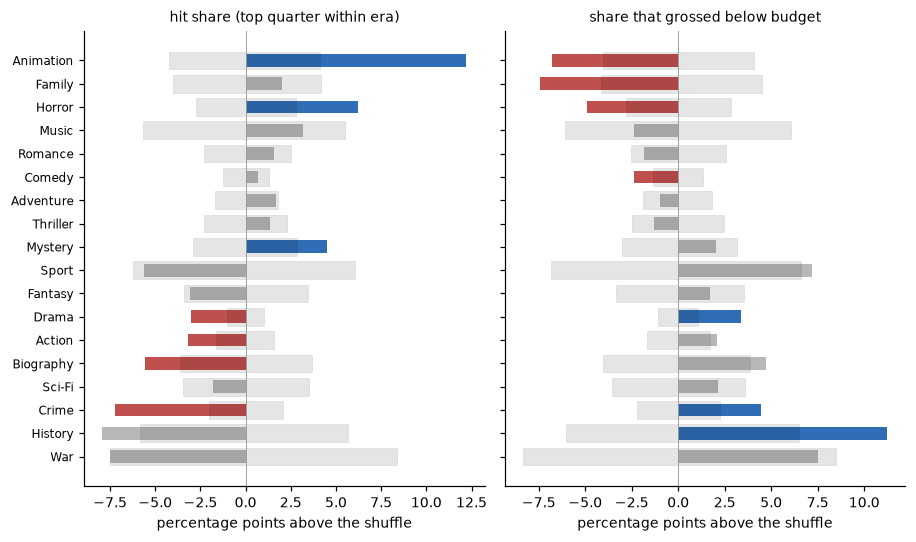

In [17]:
h = shares[shares["check"] == "hit_share"].set_index("genre").reindex(order)
b = shares[shares["check"] == "below_budget_share"].set_index("genre").reindex(order)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 5), sharey=True)
for ax, s, title in [(axes[0], h, "hit share (top quarter within era)"), (axes[1], b, "share that grossed below budget")]:
    yy = np.arange(len(s))[::-1]
    ax.barh(yy, s["excess_pp"], color=[colour({"p_holm": p, "excess": e}) for p, e in zip(s["p_holm"], s["excess_pp"])], height=.55)
    for y, lo, hi in zip(yy, s["lo95_pp"], s["hi95_pp"]):
        ax.add_patch(plt.Rectangle((lo, y - .38), hi - lo, .76, facecolor="#000", alpha=.1, edgecolor=INK, lw=.5))
    ax.axvline(0, color="#999", lw=.6)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("percentage points above the shuffle")
axes[0].set_yticks(np.arange(len(h))[::-1], h.index, fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
pd.DataFrame({"hit share": h["share"], "hit expected": h["expected"], "hit p_holm": h["p_holm"],
              "below budget share": b["share"], "below expected": b["expected"], "below p_holm": b["p_holm"]})

,hit share,hit expected,hit p_holm,below budget share,below expected,below p_holm
genre,,,,,,
Animation,0.357,0.235,0.002,0.159,0.227,0.019
Family,0.247,0.227,1.000,0.190,0.265,0.013
Horror,0.350,0.288,0.002,0.246,0.295,0.013
Music,0.290,0.258,1.000,0.276,0.299,1.000
Romance,0.260,0.244,1.000,0.279,0.297,1.000
Comedy,0.252,0.245,1.000,0.261,0.285,0.011
Adventure,0.254,0.237,0.549,0.221,0.231,1.000
Thriller,0.269,0.255,1.000,0.270,0.283,1.000
Mystery,0.304,0.259,0.031,0.315,0.294,1.000


## 10. A second source: TMDB genres and money

TMDB's genres and money figures come from different editors than IMDb's genres and Wikipedia's infoboxes. If the
result were an artefact of our sources, it would change here. (The TMDB file stays in `data/raw`; only aggregate
numbers are saved.) First, how well do the genre labels agree? Cohen's kappa corrects the agreement for chance.

In [19]:
pd.read_csv(TM / "genre_agreement.csv").sort_values("kappa", ascending=False)

,genre,imdb_films,tmdb_films,both,agreement,kappa,p_tmdb_given_imdb,p_imdb_given_tmdb
2,Animation,358,352,348,0.998,0.979,0.972,0.989
9,Horror,816,860,770,0.979,0.906,0.944,0.895
3,Comedy,2490,2411,2308,0.955,0.905,0.927,0.957
0,Action,1675,1527,1397,0.935,0.829,0.834,0.915
4,Crime,1264,1097,965,0.932,0.776,0.763,0.880
5,Drama,3211,2824,2616,0.873,0.746,0.815,0.926
10,Music,213,199,153,0.983,0.734,0.718,0.769
12,Romance,999,1075,806,0.927,0.734,0.807,0.750
1,Adventure,1344,1109,960,0.916,0.731,0.714,0.866
13,Sci-Fi,491,751,456,0.948,0.707,0.929,0.607


The main test with IMDb's genres, TMDB's genres, and consensus genres (a film counts in a genre only when both
sources give it), on the same films; then with TMDB's money instead of Wikipedia's, on the films both sources have;
then on the films Wikipedia gave no figures for, and on all films together.

In [20]:
gt = pd.read_csv(TM / "genre_tests.csv")
order_ = ["IMDb genres", "TMDB genres", "consensus genres", "Wikipedia money, films with both", "TMDB money, films with both",
          "TMDB money, films Wikipedia lacks", "union: Wikipedia, else TMDB"]
ex_ = gt.pivot(index="genre", columns="run", values="excess")[order_]
ph_ = gt.pivot(index="genre", columns="run", values="p_holm")[order_]
print({k: v for k, v in TMS["money"].items()})
(ex_.round(3).astype(str) + np.where(ph_ < .05, " *", "")).loc[main.sort_values("excess", ascending=False).index.intersection(ex_.index)]

{'usable_films_with_clean_tmdb_money': 5831, 'corr_ln_ratio_wikipedia_tmdb': 0.951, 'films_wikipedia_lacks_with_clean_tmdb_money': 677, 'union_films': 7023, 'mean_ln_ratio_usable': 0.573, 'mean_ln_ratio_wikipedia_lacks': -0.379, 'share_below_budget_usable': 0.279, 'share_below_budget_wikipedia_lacks': 0.51}


run,IMDb genres,TMDB genres,consensus genres,"Wikipedia money, films with both","TMDB money, films with both","TMDB money, films Wikipedia lacks","union: Wikipedia, else TMDB"
genre,,,,,,,
Animation,0.318 *,0.304 *,0.323 *,0.283 *,0.299 *,1.365 *,0.366 *
Family,0.268 *,0.274 *,0.254 *,0.27 *,0.275 *,0.647,0.312 *
Horror,0.214 *,0.159 *,0.227 *,0.219 *,0.26 *,-0.551,0.154 *
Music,0.13,0.021,0.062,0.036,0.048,0.704,0.219
Romance,0.081,0.109 *,0.115,0.119,0.097,0.151,0.08
Comedy,0.062 *,0.082 *,0.08 *,0.048,0.06,0.162,0.08 *
Adventure,0.044,0.071,0.091 *,0.052,0.061,0.586,0.059
Thriller,0.048,-0.136 *,-0.03,0.082,0.11,-0.363,-0.006
Mystery,0.036,0.027,0.042,0.067,0.08,-0.569,-0.03


`*` marks Holm p < .05. The films Wikipedia gives no figures for are much worse on average (printed above): half
of them grossed less than their budget. So every absolute return in the main set is too optimistic, as feared. With
those films added back, the same genres still beat or miss their budgets; Horror's edge shrinks, so part of it was
Horror's flops being missing from Wikipedia.

## 11. Content rating and Horror subgenres

Two questions TMDB makes possible. **Is a genre effect really a rating effect?** Family films are mostly PG and
Horror mostly R. The return net of budget and era on genres, with and without the film's US certification:

In [21]:
print(TMS["rating"])
display(pd.read_csv(TM / "rating_tests.csv")[["genre", "n_films", "excess", "z", "p_holm"]].rename(columns={"genre": "rating"}))
re_ = pd.read_csv(TM / "rating_genre_effects.csv")
display(re_[re_["term"].str.startswith("rating")])
re_[~re_["term"].str.startswith("rating")].pivot(index="term", columns="model", values="coef_centred").sort_values("genres only", ascending=False)

{'films_with_rating': 5735, 'spearman_genre_effects_with_vs_without_rating': 0.977}


,rating,n_films,excess,z,p_holm
0,G,117,0.562,4.990,0.001
1,PG,979,0.349,9.230,0.001
2,PG-13,1919,0.083,3.550,0.001
3,R,2720,-0.103,-5.130,0.001
4,other,611,-0.470,-7.620,0.001


,model,term,coef_centred,lo,hi
36,genres + rating,rating G vs R,0.468,0.229,0.707
37,genres + rating,rating PG vs R,0.322,0.197,0.446
38,genres + rating,rating PG-13 vs R,0.261,0.180,0.342
39,genres + rating,rating other vs R,-0.241,-0.399,-0.083


model,genres + rating,genres only
term,,
Animation,0.217,0.318
Family,0.142,0.274
Horror,0.312,0.222
Romance,0.166,0.184
Music,0.132,0.140
Mystery,0.128,0.113
Thriller,0.128,0.091
Biography,0.070,0.072
Adventure,-0.037,0.020


In [22]:
pd.read_csv(TM / "rating_mix_by_genre.csv").set_index("genre").loc[main.sort_values("excess", ascending=False).index]

,G,PG,PG-13,R,other
genre,,,,,
Animation,0.221,0.634,0.070,0.031,0.045
Family,0.101,0.796,0.068,0.000,0.035
Horror,0.000,0.013,0.200,0.678,0.109
Music,0.005,0.164,0.379,0.350,0.103
Romance,0.002,0.111,0.442,0.368,0.078
Comedy,0.031,0.236,0.317,0.333,0.083
Adventure,0.068,0.370,0.353,0.163,0.045
Thriller,0.000,0.024,0.237,0.658,0.081
Mystery,0.003,0.030,0.260,0.588,0.119


**Which Horror beats its budget?** Inside IMDb-tagged Horror, subgenres from TMDB keywords, with keyword sets fixed
before looking (see `q1_tmdb.py`). This tests the supernatural pattern from the exploratory plot words with a
different measurement (TMDB's keywords, not Wikipedia's plots), though on the same films, so it isn't new data.

In [23]:
print(TMS["horror"])
pd.read_csv(TM / "horror_subgenres.csv").drop(columns="run")

{'films': 816, 'with_keywords': 814, 'in_any_subgenre': 545}


,subgenre,n_films,mean,excess,z,p_holm,mean_other_horror,median,median_other_horror,share_beating_other_horror_median
0,supernatural,231,0.831,0.603,6.370,0.000,-0.008,0.900,0.224,0.697
1,slasher,166,0.511,0.288,2.300,0.022,0.158,0.658,0.313,0.627
2,found footage,50,1.604,1.480,5.090,0.000,0.140,1.742,0.353,0.780
3,creature,202,-0.106,-0.321,-3.280,0.003,0.340,0.250,0.478,0.436


## 12. Finer categories: Wikidata genres and a keyword network

IMDb's 18 genres are coarse. Two independent ways to get finer categories:

- **Wikidata genres** (property P136), curated by Wikidata editors and far finer ("supernatural horror film",
  "heist film", "coming-of-age film"), each also counted under its parent genre.
- **A network of TMDB keywords** (course weeks 1, 2, 4): keywords are linked when films share them more than a
  curveball null expects (every film keeps its number of keywords, every keyword its number of films), and Louvain
  finds the categories, with no labels given. Production facts, places, decades and TMDB's mood words were left out
  before any community was looked at.

First, how well Wikidata's main genres agree with IMDb's:

In [24]:
print(CATS["wikidata"])
pd.read_csv(CAT / "wikidata_agreement.csv").sort_values("kappa", ascending=False)

{'films_with_wikidata_genre': 6344, 'distinct_genres': 331, 'genres_tested': 112}


,imdb_genre,wikidata_genre,imdb_films,wikidata_films,kappa,p_wikidata_given_imdb
10,Horror,horror film,816,922,0.837,0.915
3,Biography,biographical film,467,445,0.830,0.822
0,Action,action film,1679,1722,0.747,0.825
4,Comedy,comedy film,2490,1986,0.691,0.718
5,Crime,crime film,1267,1167,0.660,0.696
6,Drama,drama film,3224,2960,0.640,0.782
14,Sci-Fi,science fiction film,491,797,0.638,0.882
15,Sport,sport film,171,166,0.601,0.602
1,Adventure,adventure film,1345,795,0.545,0.491
8,Fantasy,fantasy film,552,805,0.524,0.705


Wikidata puts "animated" and "family" mostly outside its genre property, which is why those two agree poorly. Which
Wikidata categories beat or miss their budgets (budget-decile shuffle, Holm over every category tested)?

In [25]:
wt = pd.read_csv(CAT / "wikidata_genre_tests.csv")
print(f"{(wt['p_holm'] < .05).sum()} of {len(wt)} Wikidata categories pass")
wt[wt["p_holm"] < .05].sort_values("excess", ascending=False)[["category", "films", "excess", "z", "p_holm"]].reset_index(drop=True)

22 of 112 Wikidata categories pass


,category,films,excess,z,p_holm
0,supernatural horror film,87.000,0.810,5.100,0.011
1,supernatural film,180.000,0.758,7.130,0.011
2,ghost film,121.000,0.750,5.850,0.011
3,suspense film,103.000,0.594,4.240,0.011
4,psychological thriller film,80.000,0.584,3.610,0.046
5,psychological film,95.000,0.537,3.630,0.046
6,slasher film,157.000,0.470,3.660,0.038
7,family film,233.000,0.433,6.400,0.011
8,romantic comedy film,280.000,0.389,4.840,0.011
9,buddy film,342.000,0.371,5.530,0.011


In [26]:
print("Inside IMDb Horror, Wikidata's horror subgenres against other Horror:")
pd.read_csv(CAT / "wikidata_horror_subgenres.csv").drop(columns="run")

Inside IMDb Horror, Wikidata's horror subgenres against other Horror:


,category,films,mean,excess,z,p_holm,median,median_other_horror
0,comedy horror film,42.000,-0.083,-0.291,-1.110,1.000,0.213,0.434
1,psychological horror film,29.000,0.597,0.327,1.070,1.000,0.267,0.418
2,science fiction horror film,58.000,0.206,-0.036,-0.190,1.000,0.501,0.411
3,slasher film,146.000,0.386,0.172,1.290,0.975,0.527,0.384
4,splatter film,51.000,0.174,-0.005,-0.020,1.000,0.466,0.414
5,supernatural horror film,72.000,0.993,0.740,3.960,0.002,0.985,0.364


**The keyword network.** Is there real structure? Its modularity against the same backbone rewired:

{'kept': 355, 'backbone_links': 1113, 'nodes_in_backbone': 346, 'modularity': 0.663, 'rewired_modularity_mean': 0.4993, 'rewired_modularity_max': 0.5157, 'modularity_p': 0.0196, 'mean_nmi_best_vs_other_seeds': 0.874, 'categories': 13, 'nmi_main_category_vs_rarest_imdb_genre': 0.211, 'nmi_main_category_vs_main_wikidata_genre': 0.17}


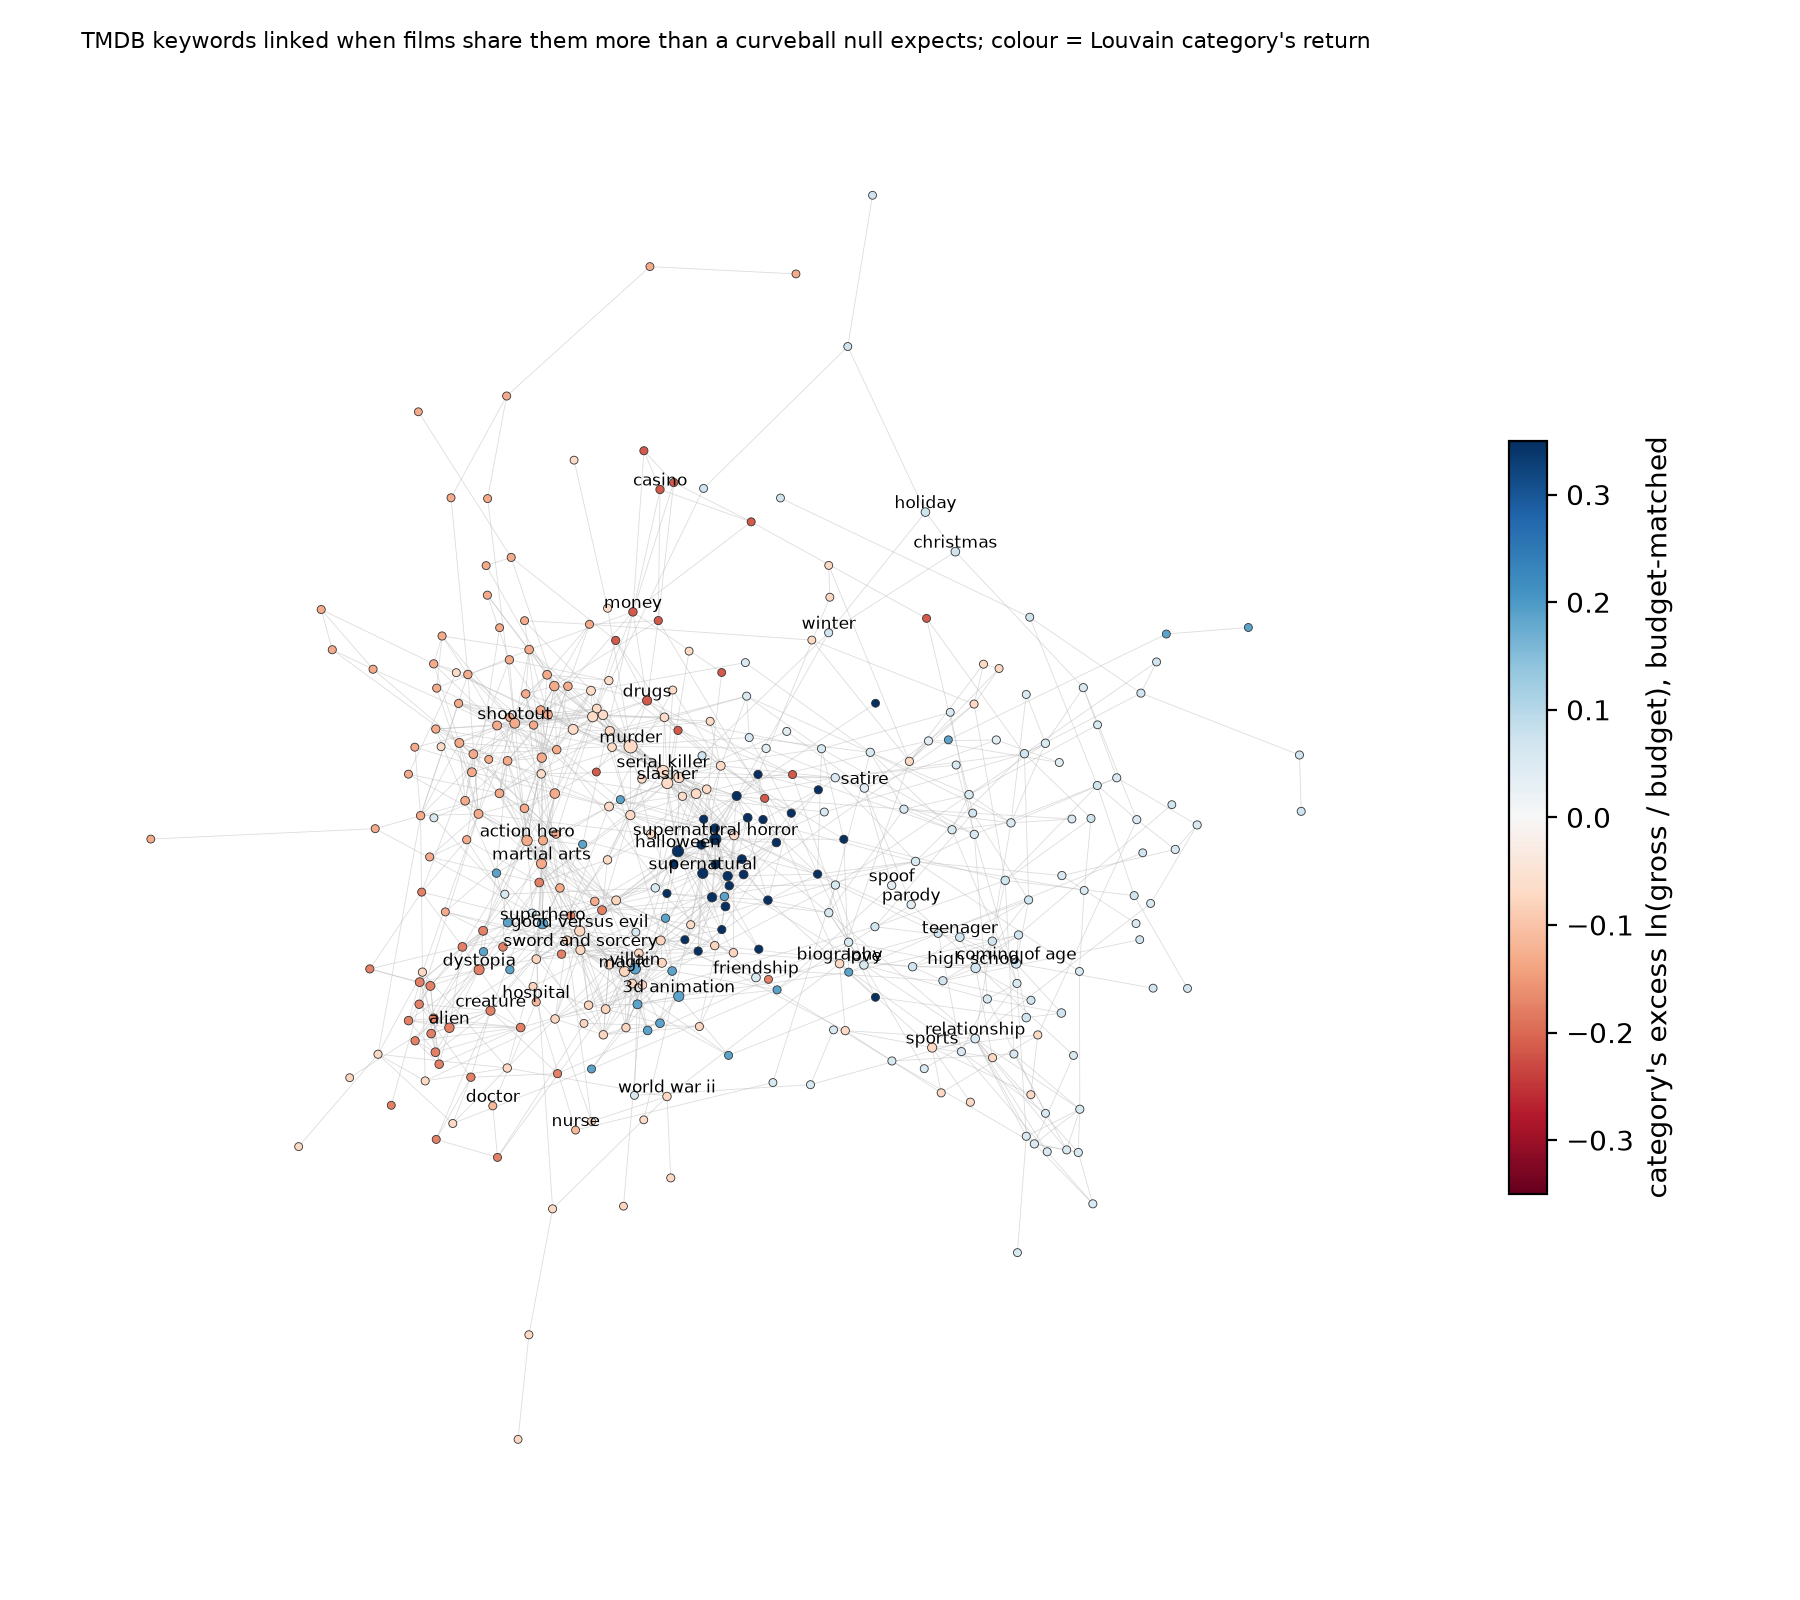

,category,keywords,top_keywords
0,1,60,"friendship, relationship, love, infidelity, gr..."
1,2,59,"action hero, martial arts, shootout, revenge, ..."
2,3,33,"murder, serial killer, slasher, psychopath, ne..."
3,4,31,"halloween, supernatural horror, supernatural, ..."
4,5,30,"high school, coming of age, teenager, gay them..."
5,6,28,"dystopia, alien, creature, future, cyberpunk, ..."
6,7,27,"sports, biography, world war ii, soldier, boxi..."
7,8,24,"good versus evil, magic, sword and sorcery, wi..."
8,9,22,"villain, superhero, 3d animation, cartoon, sup..."
9,10,14,"drugs, money, casino, las vegas, drug dealer, ..."


In [27]:
kn = CATS["keyword_network"]
print({k: kn[k] for k in ("kept", "backbone_links", "nodes_in_backbone", "modularity", "rewired_modularity_mean",
                          "rewired_modularity_max", "modularity_p", "mean_nmi_best_vs_other_seeds", "categories",
                          "nmi_main_category_vs_rarest_imdb_genre", "nmi_main_category_vs_main_wikidata_genre")})
display(Image(filename=str(CAT / "figures" / "q1_keyword_network.png"), width=700))
pd.read_csv(CAT / "keyword_categories.csv")

In [28]:
pd.read_csv(CAT / "keyword_category_tests.csv").sort_values("excess", ascending=False)[["category", "films", "excess", "z", "p_holm"]]

,category,films,excess,z,p_holm
3,4: halloween,355.500,0.350,6.770,0.001
8,9: villain,379.800,0.188,4.950,0.001
11,12: christmas,87.600,0.073,0.800,1.000
4,5: high school,454.300,0.070,1.640,0.616
0,1: friendship,900.800,0.055,1.970,0.396
10,11: satire,114.500,0.040,0.470,1.000
2,3: murder,553.900,-0.069,-1.870,0.426
6,7: sports,395.400,-0.072,-1.610,0.616
7,8: good versus evil,219.600,-0.077,-1.570,0.616
12,13: hospital,44.800,-0.115,-0.940,1.000


The categories are found without any genre labels, and their NMI with IMDb's and Wikidata's genres is modest,
so they are a different cut of the films rather than the genres again. Read their returns next to the genre result:
where the keyword horror category and Wikidata's supernatural horror agree with the TMDB-keyword subgenres, three
differently made measures point the same way.

## 13. Before release: genre specialists and script typicality

Two measures that tie genre to Q2's people and Q3's screenplays and exist before a film comes out.

**Genre specialists.** A film's team is its directors, writers, producers and first three billed actors (IMDb's
`title.principals`). Their earlier films are every earlier theatrical film they're credited on in IMDb's full
`title.basics`, noticed or not. (The first version counted only films that later got 10,000+ IMDb votes, which let
a successful past leak into "experience"; its numbers are kept below as a comparison.) Per film: the share of the
team's earlier credits in the film's genres (`genre_experience`), how many earlier credits (`prior_credits`), and how
spread over genres they are (`genre_breadth`). Outcome: the return net of budget decile and era; genre dummies and a
sequel flag held fixed. The shuffle refits exactly the reported model.

In [29]:
print(BRS["specialists"])
pd.read_csv(BR / "specialists_ols.csv")

{'films': 6316, 'films_without_earlier_credits': 30, 'sequels': 783, 'median_earlier_credits': 77.0, 'shuffle_coef_genre_experience': 0.0844, 'shuffle_p_genre_experience': 0.001, 'shuffle_model': "same as the 'sequel flag controlled' row", 'perms': 1000, 'first_version_median_earlier_credits': 36.99999999999999}


,films,term,coef_per_sd,lo,hi,p,n
0,"history: all earlier IMDb movies, sequel flag ...",genre_experience,0.084,0.032,0.137,0.002,6316
1,"history: all earlier IMDb movies, sequel flag ...",prior_credits,-0.013,-0.058,0.032,0.564,6316
2,"history: all earlier IMDb movies, sequel flag ...",genre_breadth,-0.077,-0.129,-0.026,0.003,6316
3,"history: all earlier IMDb movies, sequels left...",genre_experience,0.070,0.009,0.132,0.025,5533
4,"history: all earlier IMDb movies, sequels left...",prior_credits,-0.023,-0.072,0.026,0.355,5533
5,"history: all earlier IMDb movies, sequels left...",genre_breadth,-0.076,-0.131,-0.021,0.007,5533
6,"history: noticed films only (first version), s...",genre_experience,0.078,0.028,0.129,0.002,6150
7,"history: noticed films only (first version), s...",prior_credits,0.105,0.056,0.154,0.000,6150
8,"history: noticed films only (first version), s...",genre_breadth,-0.098,-0.156,-0.039,0.001,6150
9,"history: noticed films only (first version), s...",genre_experience,0.076,0.021,0.132,0.007,5373


**Script typicality.** How close a screenplay's embedding is to the usual screenplay of its genres. A garbled or
oddly formatted script file would also sit far from its genre, so Q3's script-quality measures (length, dialogue
share, unparsed elements, scene headings inside dialogue, upper-case and punctuation noise, tiny layers, and on the
final set the symbol-noise share) are held fixed too. If typicality only measured clean files, they would take its
coefficient away.

In [30]:
print(BRS["typicality"])
display(pd.read_csv(BR / "typicality_ols.csv"))
print("How each quality measure goes with typicality and with the return:")
pd.read_csv(BR / "typicality_quality.csv")

{'films': 1619, 'shuffle_coef': 0.1063, 'shuffle_p': 0.001, 'shuffle_model': "same as the '+ script-quality controls' row", 'perms': 1000}


,films,term,coef_per_sd,lo,hi,p,n
0,sequel flag controlled,script_typicality,0.104,0.045,0.163,0.001,1619
1,+ script-quality controls,script_typicality,0.106,0.047,0.166,0.000,1619
2,"+ script-quality controls, sequels left out",script_typicality,0.101,0.038,0.163,0.002,1429
3,"+ quality and symbol-noise controls (final 1,5...",script_typicality,0.102,0.042,0.162,0.001,1598


How each quality measure goes with typicality and with the return:


,quality_measure,spearman_with_typicality,spearman_with_net_return
0,log_tokens,-0.041,-0.057
1,dialogue_share,0.014,-0.003
2,unparsed_share,NaN,NaN
3,heading_in_dialogue_share,-0.040,0.005
4,description_upper_share,0.093,0.005
5,description_punct_share,-0.015,0.027
6,tiny_layer,0.010,0.008


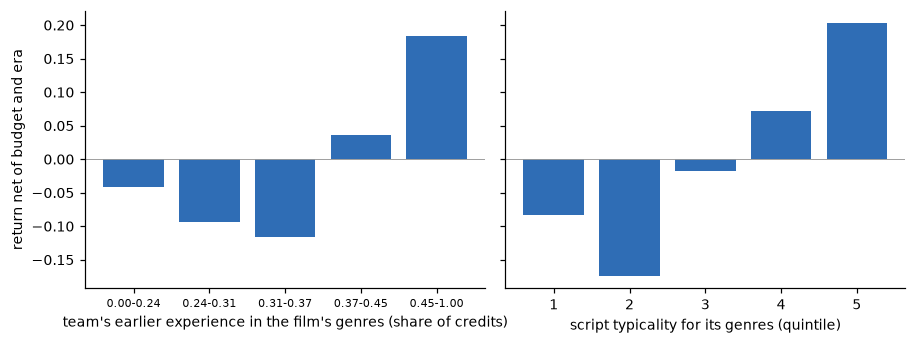

,genre,films,corr_typicality_net_return
0,Action,438,0.139
1,Adventure,342,0.119
2,Biography,157,0.130
3,Comedy,549,0.106
4,Crime,342,0.034
5,Drama,893,0.108
6,Fantasy,147,0.150
7,Horror,203,0.125
8,Mystery,198,0.174
9,Romance,231,0.172


In [31]:
sq = pd.read_csv(BR / "specialists_quintiles.csv")
tq = pd.read_csv(BR / "typicality_quintiles.csv")
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2), sharey=True)
axes[0].bar(sq["quintile"], sq["mean_net_return"], color=BLUE)
axes[0].set_xticks(sq["quintile"], sq["genre_experience_range"], fontsize=7)
axes[0].set_xlabel("team's earlier experience in the film's genres (share of credits)")
axes[0].set_ylabel("return net of budget and era")
axes[1].bar(tq["quintile"], tq["mean_net_return"], color=BLUE)
axes[1].set_xlabel("script typicality for its genres (quintile)")
for ax in axes:
    ax.axhline(0, color="#999", lw=.6)
plt.tight_layout()
plt.show()
pd.read_csv(BR / "typicality_per_genre.csv")

# Exploratory: weak evidence, not used for claims

These analyses were run and are kept for the record, with their outputs in `analysis/genre/exploratory/`. Each says in one line why it is here.

## 14. Check 4: matched pairs

*Exploratory: a different estimand from the main test, not corrected for testing 18 genres, and it repeats what the shuffle and the regression already show.*

Each film against the 5 films outside its genre with the closest budget in the same era; the mean difference
with a 95 % bootstrap interval over the genre's films. The most literal reading of "compared with films of
similar budgets". The intervals aren't corrected for the number of genres.

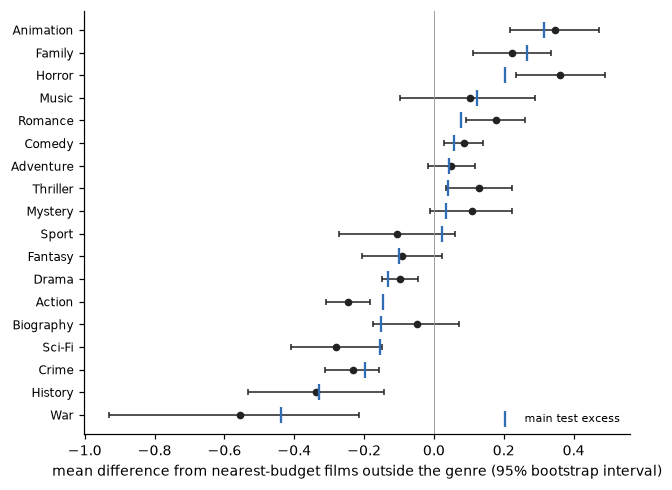

In [32]:
m = matched.set_index("genre").reindex(order[::-1])
fig, ax = plt.subplots(figsize=(6.4, 5))
yy = np.arange(len(m))
ax.errorbar(m["excess"], yy, xerr=[m["excess"] - m["lo95"], m["hi95"] - m["excess"]], fmt="o", ms=4, lw=1, capsize=2,
            color=INK)
ax.scatter(main["excess"].reindex(m.index), yy, marker="|", s=120, color=BLUE, zorder=3, label="main test excess")
ax.axvline(0, color="#999", lw=.6)
ax.set_yticks(yy, m.index, fontsize=8)
ax.set_xlabel("mean difference from nearest-budget films outside the genre (95% bootstrap interval)")
ax.legend(fontsize=7, frameon=False, loc="lower right")
plt.show()

## 15. The genre network

*Exploratory: the backbone is a fine description, but the Louvain families are no stronger than a rewired network, so testing their returns tests groups that may not exist.*

Genres are linked by the number of films that carry both (a projection of the film-genre network, week 1). Big
genres share many films just by being big, so each pair is compared with a curveball null that swaps genres
between films while keeping every film's number of genres and every genre's number of films (week 2). The links
that beat the null (Holm over all pairs) form the backbone; the disparity filter (week 4) is the second method.
Louvain (week 4) splits the backbone into genre families, and its modularity is compared with the same backbone
rewired.

153 genre pairs, 1000 null samples
backbone (null model): 41 links; disparity filter: 24; both: 21, null only: 20, disparity only: 3
Louvain: 3 families, modularity 0.391 (seeds [0.3797, 0.3905]), agreement across seeds NMI 0.77
rewired backbone: modularity 0.398 on average, max 0.517; p = 0.6219


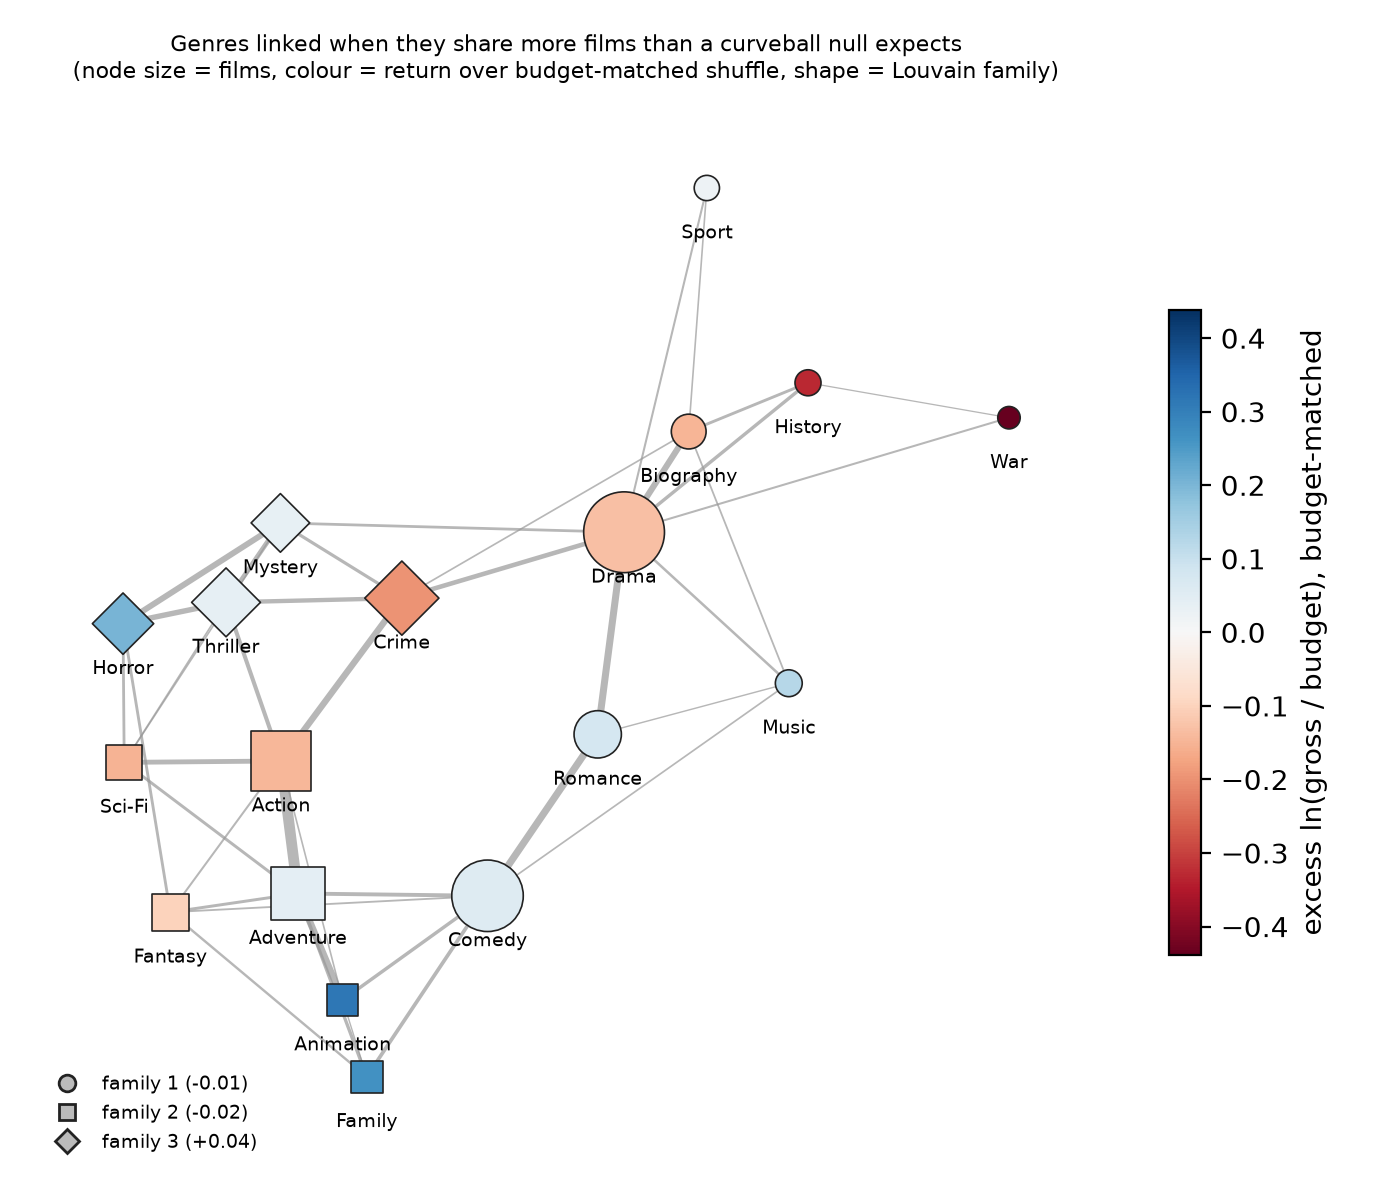

In [33]:
print(f"{SN['genre_network']['pairs']} genre pairs, {SN['genre_network']['null_samples']} null samples")
g = SN["genre_network"]
print(f"backbone (null model): {g['backbone_links']} links; disparity filter: {g['disparity_links']}; both: {g['both']}, "
      f"null only: {g['backbone_only']}, disparity only: {g['disparity_only']}")
print(f"Louvain: {g['families']} families, modularity {g['modularity']:.3f} (seeds {g['modularity_min_max_over_seeds']}), "
      f"agreement across seeds NMI {g['mean_nmi_best_vs_other_seeds']:.2f}")
print(f"rewired backbone: modularity {g['null_modularity_mean']:.3f} on average, max {g['null_modularity_max']:.3f}; p = {g['modularity_p']}")
display(Image(filename=str(NET / "figures" / "q1_genre_network.png"), width=650))

In [34]:
print("Strongest links over the null:")
pairs[pairs["backbone"]].sort_values("z", ascending=False).head(12).reset_index(drop=True)

Strongest links over the null:


,genre_a,genre_b,films_both,expected,z,p_holm,p_empirical,backbone,disparity_filter
0,Adventure,Animation,317,51.070,41.650,0.000,0.001,True,True
1,Action,Adventure,716,261.000,34.610,0.000,0.001,True,True
2,Horror,Mystery,288,62.820,32.880,0.000,0.001,True,True
3,Biography,History,93,8.890,28.570,0.000,0.001,True,True
4,Biography,Drama,422,187.260,23.800,0.000,0.001,True,True
5,Horror,Thriller,296,93.720,23.350,0.000,0.001,True,True
6,Action,Sci-Fi,265,90.670,21.560,0.000,0.001,True,True
7,Comedy,Romance,580,299.570,20.970,0.000,0.001,True,True
8,Mystery,Thriller,253,83.510,20.620,0.000,0.001,True,False
9,Drama,Romance,690,412.120,20.070,0.000,0.001,True,True


In [35]:
print("Weakest (pairs that co-occur less than chance):")
pairs.sort_values("z").head(6).reset_index(drop=True)

Weakest (pairs that co-occur less than chance):


,genre_a,genre_b,films_both,expected,z,p_holm,p_empirical,backbone,disparity_filter
0,Comedy,Thriller,54,321.040,-19.380,0.000,0.001,False,False
1,Adventure,Drama,291,563.060,-16.680,0.000,0.001,False,False
2,Action,Drama,467,712.460,-14.960,0.000,0.001,False,False
3,Comedy,Mystery,48,215.990,-14.530,0.000,0.001,False,False
4,Action,Romance,28,190.480,-14.090,0.000,0.001,False,False
5,Comedy,Drama,867,"1,100.030",-12.440,0.000,0.001,False,True


Each family's return, with every film split across families by its share of genres, against the
budget-decile shuffle:

In [36]:
families

,family,genres,films_weighted,films_any,mean,excess,lo95,hi95,z,p_holm
0,1,Biography|Comedy|Drama|History|Music|Romance|S...,"3,222.700",4933,0.543,-0.006,-0.025,0.025,-0.490,0.627
1,2,Action|Adventure|Animation|Family|Fantasy|Sci-Fi,"1,659.800",2988,0.585,-0.019,-0.033,0.033,-1.120,0.532
2,3,Crime|Horror|Mystery|Thriller,"1,449.500",2668,0.611,0.036,-0.048,0.049,1.460,0.431


The families are what genres *travel with*. If returns belonged to families, the families would differ here;
the main test's winners and losers sit in the same families instead (Animation next to Action, Horror next to
Crime), so the return effect belongs to single genres.

## 16. Do films made by the same people share genre?

*Exploratory: the null shuffles away all structure, so a huge z was guaranteed; people repeating genres is expected and largely sequels and franchises.*

Films are linked when they share a director, writer, producer or one of the first three billed actors. For each
genre, the assortativity coefficient of its 0/1 indicator on that network (week 3, mixing patterns), against the
genre sets shuffled between films of the same era (each film keeps its links). This is the link between Q1 and
Q2: if people stick to genres, part of what Q2's network measures is genre.

6,346 films, 18,868 people, 180,396 links, mean degree 56.85, 85 films without a link
links whose two films share a genre: 71.8% (shuffle 55.8%, 97.5th pct 56.4%, p 0.001)


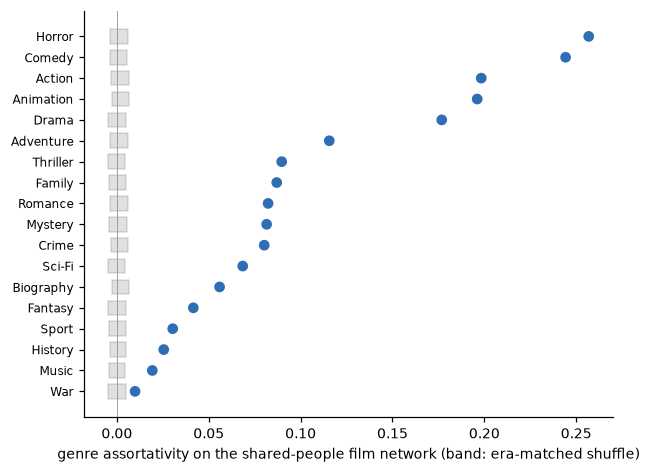

,genre,n_films,assortativity,null_mean,null_lo95,null_hi95,z,p_holm
0,Horror,816,0.257,0.001,-0.004,0.006,101.800,0.018
1,Comedy,2490,0.244,0.001,-0.004,0.006,101.600,0.018
2,Action,1679,0.198,0.002,-0.003,0.006,79.600,0.018
3,Animation,358,0.196,0.002,-0.003,0.007,79.000,0.018
4,Drama,3224,0.177,0.000,-0.005,0.005,75.500,0.018
5,Adventure,1345,0.116,0.001,-0.004,0.006,45.100,0.018
6,Thriller,1069,0.090,-0.000,-0.005,0.004,38.200,0.018
7,Family,368,0.087,0.000,-0.004,0.005,36.200,0.018
8,Romance,1001,0.082,0.001,-0.004,0.006,34.000,0.018
9,Mystery,731,0.082,0.001,-0.004,0.005,34.300,0.018


In [37]:
fn = SN["film_network"]
print(f"{fn['films']:,} films, {fn['people']:,} people, {fn['links']:,} links, mean degree {fn['mean_degree']}, "
      f"{fn['films_with_no_link']} films without a link")
print(f"links whose two films share a genre: {fn['share_links_sharing_a_genre']:.1%} "
      f"(shuffle {fn['share_null_mean']:.1%}, 97.5th pct {fn['share_null_hi95']:.1%}, p {fn['share_p']})")
a_ = assort.sort_values("assortativity")
fig, ax = plt.subplots(figsize=(6.2, 4.8))
yy = np.arange(len(a_))
for k, (_, r) in enumerate(a_.iterrows()):
    ax.add_patch(plt.Rectangle((r["null_lo95"], k - .35), r["null_hi95"] - r["null_lo95"], .7, color="#000", alpha=.12))
ax.scatter(a_["assortativity"], yy, color=[BLUE if p < .05 else GREY for p in a_["p_holm"]], zorder=3)
ax.set_yticks(yy, a_["genre"], fontsize=8)
ax.axvline(0, color="#999", lw=.6)
ax.set_xlabel("genre assortativity on the shared-people film network (band: era-matched shuffle)")
plt.show()
a_.sort_values("assortativity", ascending=False).reset_index(drop=True)

## 17. Other ways to say what genre a film is

*Exploratory: Tag Genome and plots are written after release and carry reception; plot clusters are a null result.*

IMDb's genres are up to three unweighted tags. The Tag Genome gives each film a share per genre from what users
tagged; the plot shares predict the same from the Wikipedia plot's embedding; and k-means on the plot embeddings
makes genres from text alone (weeks 6 and 7). How far do they agree, and which predicts returns best?

In [38]:
print(f"films: {SS['films']:,}; with Tag Genome {SS['with_tag_genome']:,}; with a plot vector {SS['with_plot_vector']:,}; "
      f"with all {SS['films_with_all']:,}. k-means k = {SS['kmeans_k']}, stability across seeds NMI {SS['kmeans_mean_nmi_best_vs_other_seeds']}")
agreement

films: 6,346; with Tag Genome 4,231; with a plot vector 6,303; with all 4,203. k-means k = 18, stability across seeds NMI 0.699


,a,b,nmi,share_of_films,null_mean
0,tag_genome_dominant,plot_dominant,0.290,NaN,NaN
1,tag_genome_dominant,plot_cluster,0.256,NaN,NaN
2,plot_dominant,plot_cluster,0.290,NaN,NaN
3,tag_genome_dominant,one of the film's IMDb genres,NaN,0.869,0.248
4,plot_dominant,one of the film's IMDb genres,NaN,0.786,0.325


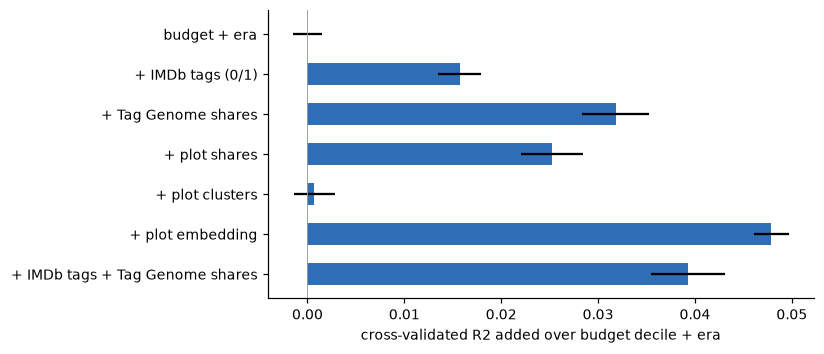

,model,cv_r2,sd_over_repeats,features,added_over_budget_era
0,budget + era,0.094,0.002,15,0.000
1,+ IMDb tags (0/1),0.109,0.002,33,0.016
2,+ Tag Genome shares,0.126,0.004,33,0.032
3,+ plot shares,0.119,0.003,33,0.025
4,+ plot clusters,0.094,0.002,33,0.001
5,+ plot embedding,0.142,0.002,399,0.048
6,+ IMDb tags + Tag Genome shares,0.133,0.004,51,0.039


In [39]:
c2 = cv.copy()
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(c2["model"][::-1], c2["added_over_budget_era"][::-1], xerr=c2["sd_over_repeats"][::-1], color=BLUE, height=.55)
ax.axvline(0, color="#999", lw=.6)
ax.set_xlabel("cross-validated R2 added over budget decile + era")
plt.show()
cv

The plot embedding adds the most, but a Wikipedia plot is written after release and the embedding has hundreds
of numbers, so part of it can be how famous the film is rather than what it is about. The plot clusters, which
know nothing about returns, add almost nothing. The weighted Tag Genome shares do better than IMDb's 0/1 tags.

In [40]:
tg = share_tests[share_tests["films"] == "tag_genome"].pivot(index="genre", columns="representation", values=["excess", "p_holm"])
tg.sort_values(("excess", "imdb_tags"), ascending=False)

excess                                          p_holm  \
representation imdb_tags tag_genome_dominant tag_genome_shares imdb_tags   
genre                                                                      
Animation          0.296               0.281             0.158     0.002   
Family             0.211               0.444             0.392     0.021   
Horror             0.134               0.135             0.111     0.341   
Adventure          0.086               0.028             0.064     0.091   
Romance            0.064               0.180             0.121     1.000   
Thriller           0.049              -0.043            -0.026     1.000   
Comedy             0.033               0.206             0.138     1.000   
Music             -0.001              -0.084             0.061     1.000   
Sport             -0.017              -0.005             0.035     1.000   
Action            -0.022               0.078            -0.010     1.000   
Fantasy           -0.049              -0.287            -0.095     1.000   
Sci-Fi            -0.064              -0.138            -0.220     1.000   
Mystery           -0.081              -0.382            -0.119     1.000   
Drama             -0.123              -0.176            -0.153     0.002   
Biography         -0.163              -0.197            -0.170     0.365   
Crime             -0.193              -0.456            -0.179     0.002   
History           -0.236              -0.192            -0.006     0.390   
War               -0.282              -0.473            -0.198     0.608   

                                                      
representation tag_genome_dominant tag_genome_shares  
genre                                                 
Animation                    0.003             0.190  
Family                       0.026             0.002  
Horror                       0.467             0.511  
Adventure                    1.000             0.077  
Romance                      0.187             0.005  
Thriller                     1.000             1.000  
Comedy                       0.002             0.002  
Music                        1.000             1.000  
Sport                        1.000             1.000  
Action                       0.467             1.000  
Fantasy                      0.018             0.080  
Sci-Fi                       0.401             0.002  
Mystery                      0.187             0.234  
Drama                        0.003             0.002  
Biography                    0.467             0.149  
Crime                        0.002             0.003  
History                      1.000             1.000  
War                          0.013             0.077

Same films, three ways to count genre: IMDb's tags, each film split by its Tag Genome shares, and each film
given its single dominant Tag Genome genre (no overlap, so the tests are separate). The plot clusters, described
by their most common IMDb genres:

In [41]:
clusters.sort_values("excess", ascending=False).reset_index(drop=True)

,cluster,films,mean_ln_ratio,top_imdb_genres,excess,z,p_holm
0,5,239,0.869,"Animation 31%, Comedy 27%, Family 10%",0.173,2.390,0.270
1,11,404,0.876,"Comedy 36%, Drama 29%, Romance 25%",0.168,2.810,0.081
2,13,121,0.949,"Action 36%, Drama 17%, Animation 16%",0.127,1.090,1.000
3,4,226,0.823,"Horror 56%, Drama 11%, Action 7%",0.079,0.940,1.000
4,16,172,0.718,"Sport 38%, Comedy 25%, Drama 12%",0.037,0.410,1.000
5,7,219,0.696,"Drama 41%, Comedy 20%, Romance 12%",0.032,0.390,1.000
6,12,162,0.713,"Action 37%, Drama 15%, Comedy 11%",0.026,0.280,1.000
7,8,180,0.664,"Fantasy 26%, Action 18%, Animation 17%",-0.018,-0.240,1.000
8,10,364,0.726,"Horror 31%, Comedy 12%, Drama 12%",-0.026,-0.400,1.000
9,1,409,0.686,"Comedy 45%, Drama 32%, Romance 8%",-0.028,-0.460,1.000


## 18. Inside Horror: which plot words go with beating the budget

*Exploratory: post-release text, post-hoc word set, and it does not replicate in the screenplays.*

Horror films are split by their return net of budget decile and era: top quarter against bottom quarter. Their
Wikipedia plots are compared word by word with the log-odds ratio and an informative Dirichlet prior (week 6;
the statistic Q3 uses on scripts), and the labels are shuffled within budget deciles. Character names are dropped
(words mostly capitalised mid-sentence). Only words and counts are shown; no plot text.

In [42]:
print(f"{SW['films_with_plot']} Horror films with a plot; {SW['hits']} above, {SW['flops']} below; vocabulary {SW['vocab']:,} words")
print(f"largest |calibrated z| {SW['max_abs_calibrated_z']}, family-wise shuffle p {SW['familywise_p_max_abs_calibrated_z']}")
print(f"median plot length: {SW['median_plot_words_hit']} words (above), {SW['median_plot_words_flop']} (below)")
wlists

815 Horror films with a plot; 204 above, 204 below; vocabulary 2,122 words
largest |calibrated z| 4.32, family-wise shuffle p 0.004
median plot length: 622 words (above), 645 (below)


,side,k,kth_calibrated_z,p
0,hit,5,3.400,0.001
1,hit,10,3.260,0.001
2,hit,20,2.860,0.001
3,flop,5,3.420,0.001
4,flop,10,3.170,0.001
5,flop,20,2.920,0.001


In [43]:
t = wtop.assign(rank=wtop.groupby("side").cumcount() + 1).pivot(index="rank", columns="side", values="word")
t["hit z"] = wtop[wtop.side == "hit"]["calibrated_z"].to_numpy()
t["flop z"] = wtop[wtop.side == "flop"]["calibrated_z"].to_numpy()
t[["hit", "hit z", "flop", "flop z"]]

side,hit,hit z,flop,flop z
rank,,,,
1,demon,3.890,fight,-4.320
2,receives,3.750,him,-3.590
3,paranormal,3.430,human,-3.580
4,possessed,3.430,upon,-3.480
5,house,3.400,of,-3.420
6,game,3.350,run,-3.420
7,haunting,3.340,hold,-3.320
8,demonic,3.310,off,-3.310
9,night,3.280,this,-3.280


The words describe the plots as Wikipedia editors remember them, so they can't separate what made a film work
from how its story is told afterwards. They do say what kind of Horror beats its budget.

## 19. Inside Horror, in the screenplays

*Exploratory: the replication attempt of the plot words; it fails.*

The word test of the Horror-plot section on the screenplays instead of the Wikipedia plots (Q3's preprocessing,
description and dialogue layers), and the same supernatural word set counted in the scripts. It does not replicate.

In [44]:
print({k: v for k, v in HSS.items() if k != "supernatural_in_script"})
print("supernatural words in the script:", HSS["supernatural_in_script"])
hw = pd.read_csv(HSC / "horror_script_words.csv")
pd.DataFrame({(l, sd): hw[(hw.layer == l) & (hw.side == sd)]["word"].head(10).to_numpy()
              for l in ("description", "dialogue") for sd in ("hit", "flop")})

{'films_with_script': 203, 'hits': 51, 'flops': 51, 'perms': 1000, 'description_vocab': 5901, 'description_familywise_p': 0.3956, 'description_supernatural_words_in_vocab': ['demon', 'demonic', 'haunting', 'possessed'], 'dialogue_vocab': 2857, 'dialogue_familywise_p': 0.2128, 'dialogue_supernatural_words_in_vocab': ['demon', 'supernatural']}
supernatural words in the script: {'films': 133, 'share': 0.655, 'net_supernatural': 0.694, 'net_other': 0.526, 'difference': 0.167, 'p': 0.3459}


description              dialogue          
            hit        flop       hit      flop
0        closet     release  vacation    nothin
1      anywhere     quarter       dad      dirt
2         messy  apparently      hang  attitude
3        living    battered     ended  straight
4       thunder    unlocked       mom    forest
5         drain       choke  practice         v
6         house     roaring     class   presses
7        candle     himself  romantic      burn
8  illuminating     shotgun     point     squad
9           egg      flames   moments     human

In [45]:
pd.read_csv(HSC / "horror_script_list_null.csv").pivot(index=["layer", "side"], columns="k", values="p")

k                   5     10    20
layer       side                  
description flop 0.061 0.009 0.024
            hit  0.660 0.802 0.674
dialogue    flop 0.095 0.078 0.184
            hit  0.242 0.295 0.274

## 20. The genre distribution through the same analyses

*Exploratory: post-release measure that carries reception, with many variants tried.*

`notebooks/tag_shares.ipynb` turned each film's Tag Genome genre scores into shares that add up to 1. Here every
follow-up above is rerun with those shares as weights, next to the 0/1 tags on the same films (the films with
Tag Genome scores, which stop in 2014). `notebooks/tag_profit.ipynb` found that tag scores carry audience size, so
the first question is whether the shares do too.

In [46]:
lk = pd.read_csv(SF / "leak.csv")
print(f"{SFS['films']:,} films with Tag Genome shares")
lk.pivot(index="model", columns="target", values="added").loc[["+ IMDb tags", "+ Tag Genome shares"]]

4,231 films with Tag Genome shares


target,ln_ratio,ln_ratio_votes_in_base,ln_votes
model,,,
+ IMDb tags,0.016,0.033,0.021
+ Tag Genome shares,0.030,0.054,0.018


`ln_votes`: how much each adds to predicting ln(IMDb votes) beyond budget and era; if the shares carried
audience size they would add more here than the tags. `ln_ratio_votes_in_base`: what each adds to the return when
ln(votes) is already in the model (votes are partly the outcome, so this is a sensitivity check).

tiers with 0/1 tags: 5 of 59 cells pass: Crime $5-30M -0.19, Drama $5-30M -0.12, Animation $30-100M +0.47, Comedy $30-100M +0.10, Drama $30-100M -0.10
tiers with shares: 9 of 48 cells pass: Comedy $5-30M +0.14, Crime $5-30M -0.27, Drama $5-30M -0.15, Family $5-30M +0.48, Romance $5-30M +0.18, Sci-Fi $5-30M -0.39, Animation $30-100M +0.31, Drama $30-100M -0.13, Family $30-100M +0.32


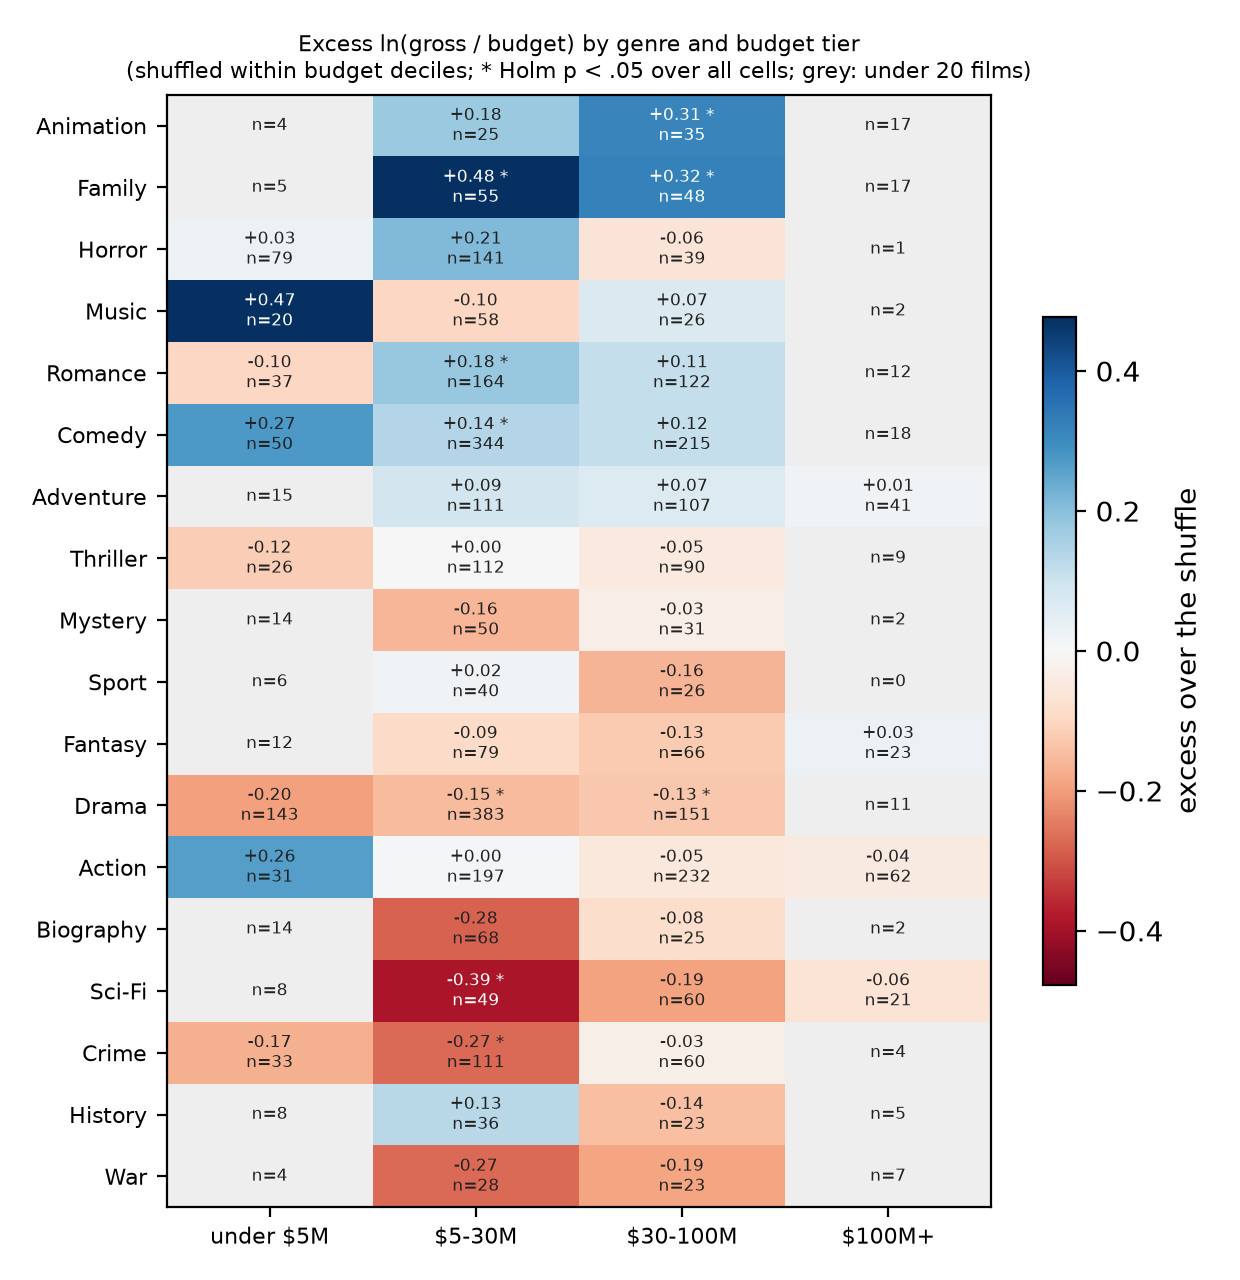

In [47]:
t_imdb = pd.read_csv(SF / "tiers_imdb_tags.csv")
t_sh = pd.read_csv(SF / "tiers_tag_genome_shares.csv")
for name, t in (("0/1 tags", t_imdb), ("shares", t_sh)):
    ok = t[t["excess"].notna()]
    print(f"tiers with {name}: {(ok['p_holm'] < .05).sum()} of {len(ok)} cells pass: "
          + ", ".join(f"{r['genre']} {r['tier']} {r['excess']:+.2f}" for _, r in ok[ok['p_holm'] < .05].iterrows()))
display(Image(filename=str(SF / "figures" / "q1_tiers_tag_genome_shares.png"), width=520))

In [48]:
sm_i = pd.read_csv(SF / "smooth_imdb_tags.csv").set_index("genre")
sm_s = pd.read_csv(SF / "smooth_tag_genome_shares.csv").set_index("genre")
hs_i = pd.read_csv(SF / "hitshare_imdb_tags.csv")
hs_s = pd.read_csv(SF / "hitshare_tag_genome_shares.csv")
hit = lambda d: d[d["check"] == "hit_share"].set_index("genre")
pd.DataFrame({"smooth, tags": sm_i["excess"], "p": sm_i["p_holm"], "smooth, shares": sm_s["excess"], "p ": sm_s["p_holm"],
              "hit pp, tags": hit(hs_i)["excess_pp"], "hit pp, shares": hit(hs_s)["excess_pp"]}).sort_values("smooth, shares", ascending=False)

,"smooth, tags",p,"smooth, shares",p,"hit pp, tags","hit pp, shares"
genre,,,,,,
Family,0.220,0.021,0.349,0.002,2.160,9.420
Animation,0.290,0.010,0.170,0.226,14.070,8.060
Romance,0.108,0.088,0.155,0.002,2.670,3.970
Comedy,0.043,0.442,0.141,0.002,0.700,2.810
Horror,0.136,0.107,0.121,0.226,0.750,1.130
Sport,-0.059,1.000,0.034,1.000,-5.860,-3.950
Music,0.026,1.000,0.030,1.000,2.370,-0.610
History,-0.233,0.442,0.011,1.000,-8.390,-2.210
Adventure,0.020,1.000,-0.004,1.000,2.870,1.280


**Genre mix.** A film's effective number of genres (1 / sum of squared shares) is how spread its mix is. Mean
return per quintile of it, and per IMDb number of genres, against the budget-decile shuffle:

In [49]:
sp = pd.read_csv(SF / "spread.csv")
print({k: v for k, v in SFS["spread"].items()})
sp

{'spearman_effective_genres_vs_budget_netted_return': 0.112, 'p': 2.35e-13, 'spearman_effective_genres_vs_budget_netted_ln_votes': 0.167, 'spearman_imdb_n_genres_vs_budget_netted_ln_votes': -0.025}


,measure,group,films,mean,excess,z,p_holm
0,effective_genres_tag_genome,q1 (1.04-2.09),847,0.655,-0.118,-2.950,0.010
1,effective_genres_tag_genome,q2 (2.09-2.73),846,0.571,-0.113,-2.950,0.010
2,effective_genres_tag_genome,q3 (2.73-3.40),846,0.602,-0.089,-2.310,0.039
3,effective_genres_tag_genome,q4 (3.40-4.34),846,0.699,0.024,0.670,0.500
4,effective_genres_tag_genome,q5 (4.34-10.30),846,0.973,0.296,8.480,0.001
5,imdb_n_genres,1 genre,347,1.046,0.238,3.340,0.001
6,imdb_n_genres,2 genres,1090,0.772,0.057,1.710,0.089
7,imdb_n_genres,3 genres,2794,0.629,-0.052,-3.750,0.001


The two measures point opposite ways: films with one IMDb genre beat their budgets, while films the Tag Genome
sees as most mixed do too. The spread of the Tag Genome mix goes with IMDb votes (printed above), so a broad mix
partly means a widely seen film, as `tag_profit.ipynb` found; IMDb's count of genres does not.

In [50]:
sn = SFS["share_network"]
print(f"share network: {sn['backbone_links']} backbone links ({sn['shared_links']} also in the IMDb-tag backbone of "
      f"{sn['imdb_backbone_links']}); Louvain {sn['families']} families, modularity {sn['modularity']}; "
      f"NMI with the IMDb-tag families {sn['nmi_with_imdb_families']}")
pd.read_csv(SF / "share_network_families.csv")

share network: 34 backbone links (22 also in the IMDb-tag backbone of 41); Louvain 5 families, modularity 0.1391; NMI with the IMDb-tag families 0.412


,family,genres
0,1,Biography|Crime|Drama|History|Music|Mystery|Th...
1,2,Action|Adventure|Fantasy|Horror|Sci-Fi
2,3,Animation|Comedy|Family|Romance
3,4,Sport
4,5,War


In [51]:
asr = pd.read_csv(SF / "assortativity.csv").pivot(index="genre", columns="representation", values="assortativity")
asr.sort_values("tag_genome_shares", ascending=False)

representation,imdb_tags,tag_genome_shares
genre,,
Comedy,0.255,0.309
Horror,0.175,0.265
Action,0.188,0.254
Drama,0.179,0.181
Animation,0.189,0.163
Family,0.096,0.155
Romance,0.085,0.115
Crime,0.085,0.096
Adventure,0.091,0.094


**Horror words, three ways.** The same word test as the Horror-plot section on (a) every IMDb-tagged Horror film,
(b) IMDb-tagged Horror films with Tag Genome scores, (c) films whose largest Tag Genome share is Horror. If (b) and
(c) agree with each other but not with (a), the difference comes from which films are in (the Tag Genome stops in
2014), not from how Horror is defined.

In [52]:
runs = {"(a) IMDb Horror": "horror", "(b) IMDb Horror, Tag Genome films": "horror_imdb_on_tag_genome",
        "(c) Tag Genome Horror": "horror_tag_genome"}
cols = {}
for name, tag in runs.items():
    s_ = json.loads((WRD / f"{tag}_summary.json").read_text())
    t_ = pd.read_csv(WRD / f"{tag}_top.csv")
    print(f"{name}: {s_['films_with_plot']} films, {s_['hits']} vs {s_['flops']}, family-wise p {s_['familywise_p_max_abs_calibrated_z']}")
    cols[(name, "above")] = t_[t_.side == "hit"]["word"].head(10).to_numpy()
    cols[(name, "below")] = t_[t_.side == "flop"]["word"].head(10).to_numpy()
pd.DataFrame(cols)

(a) IMDb Horror: 815 films, 204 vs 204, family-wise p 0.004
(b) IMDb Horror, Tag Genome films: 441 films, 111 vs 111, family-wise p 0.04
(c) Tag Genome Horror: 351 films, 88 vs 88, family-wise p 0.0819


(a) IMDb Horror        (b) IMDb Horror, Tag Genome films           \
            above  below                             above    below   
0           demon  fight                          receives       of   
1        receives    him                           footage    human   
2      paranormal  human                             walls    fight   
3       possessed   upon                              them     upon   
4           house     of                           murders  manages   
5            game    run                           removed     hold   
6        haunting   hold                         boyfriend     part   
7         demonic    off                            rushes    plans   
8           night   this                          children  mansion   
9         footage  fully                          supplies    dance   

  (c) Tag Genome Horror             
                  above      below  
0              receives      dance  
1             boyfriend     reveal  
2              children  collapses  
3                 walls    mansion  
4                 there     eating  
5               murders         of  
6                  them         as  
7                inside        led  
8               removed        off  
9                closet         up

## 21. Fixing the genre distribution's weaknesses

*Exploratory: careful, but it repairs a measure the analysis doesn't rely on; the script-predicted shares learn from a target that carries reception.*

The section before used the Tag Genome shares as they were built for `tag_shares.ipynb`. A critical look found six
problems: the shares carry reception (ratings, critics), the power of 2 in their construction was arbitrary and moved
the result, the films covered are older and much-tagged, everything in them is measured after release, each genre
rested on one tag, and the "effective number of genres" partly measured fame. `q1_share_fixes.py` fixes each one,
choosing every setting from agreement with IMDb's labels and never from returns.

**Which tag scores each genre.** Each genre's candidate tags (and their mean) against IMDb's label, by AUC; the
best is kept. The old mapping is marked `current`.

In [53]:
mp = pd.read_csv(FX / "mapping.csv")
print("genres whose tag changed:", ", ".join(FXS["mapping_changed"]))
mp[mp["chosen"] | mp["current"]].reset_index(drop=True)

genres whose tag changed: Biography, Comedy, Family, History, Romance, Thriller


,genre,candidate,auc,current,chosen
0,Action,action,0.946,True,True
1,Adventure,adventure,0.909,True,True
2,Animation,animation,0.996,True,True
3,Biography,biographical,0.962,True,False
4,Biography,"mean of biographical, biography, true story",0.969,False,True
5,Comedy,comedy,0.937,True,False
6,Comedy,"mean of comedy, funny",0.940,False,True
7,Crime,crime,0.895,True,True
8,Drama,drama,0.861,True,True
9,Family,kids and family,0.879,True,False


**Which power.** Shares = relevance to the power p, divided by the film's total. p is chosen by how well each
share reproduces IMDb's label (cross-validated log loss, lower is better):

In [54]:
pw = pd.read_csv(FX / "power.csv")
print(f"chosen power: {FXS['power_chosen']}")
pw

chosen power: 1.5


,power,mean_cv_log_loss_imdb_labels
0,0.500,0.256
1,1.000,0.206
2,1.500,0.198
3,2.000,0.201
4,3.000,0.210
5,4.000,0.220


**Shares, total tagging and reception.** Raw relevance mixes how much a film is tagged at all (which goes with
fame) with what kind of film it is. The log of the total enters as its own variable; rating and ln(votes) go into
the base model so that the shares are judged on what they add beyond reception. CV R2 added over each base:

In [55]:
cr = pd.read_csv(FX / "cv_r2.csv")
cr[cr["films"].str.startswith("tag_genome") | cr["films"].str.startswith("films with")].reset_index(drop=True)

,films,model,cv_r2,added
0,tag_genome_films,IMDb tags,0.109,0.016
1,tag_genome_films,"shares (old mapping, p=2)",0.122,0.030
2,tag_genome_films,shares (chosen),0.129,0.036
3,tag_genome_films,log total only,0.148,0.055
4,tag_genome_films,shares (chosen) + log total,0.222,0.129
5,tag_genome_films,raw relevance,0.221,0.128
6,tag_genome_films,shares p=0.5,0.157,0.064
7,tag_genome_films,shares p=1,0.139,0.046
8,tag_genome_films,shares p=1.5,0.129,0.036
9,tag_genome_films,shares p=2,0.123,0.030


In [56]:
print("What each one predicts besides returns (CV R2 added over budget + era):")
cr[cr["films"].str.startswith("target")].reset_index(drop=True)

What each one predicts besides returns (CV R2 added over budget + era):


,films,model,cv_r2,added
0,target rating,IMDb tags,0.231,0.191
1,target rating,shares (chosen),0.303,0.264
2,target rating,log total only,0.094,0.054
3,target ln_votes,IMDb tags,0.265,0.021
4,target ln_votes,shares (chosen),0.271,0.027
5,target ln_votes,log total only,0.350,0.106


The log total predicts votes far better than it predicts anything about genre, so it is mostly fame; the
shares on their own predict IMDb rating better than the tags do, so they carry some reception. With rating and
votes held fixed, the shares still add more than the tags.

In [57]:
ge = pd.read_csv(FX / "genre_effects.csv").pivot(index="genre", columns="representation", values="coef_centred")
print("rank agreement of genre effects (Spearman):", FXS["spearman_effects"])
ge.sort_values("IMDb tags", ascending=False)

rank agreement of genre effects (Spearman): {'IMDb tags ~ IMDb tags, rating and votes fixed': 0.767, 'IMDb tags ~ shares + log total': 0.618, 'IMDb tags ~ shares + log total, rating and votes fixed': 0.598, 'IMDb tags, rating and votes fixed ~ shares + log total': 0.649, 'IMDb tags, rating and votes fixed ~ shares + log total, rating and votes fixed': 0.759, 'shares + log total ~ shares + log total, rating and votes fixed': 0.924}


representation,IMDb tags,"IMDb tags, rating and votes fixed",shares + log total,"shares + log total, rating and votes fixed"
genre,,,,
Animation,0.321,0.369,-0.657,-0.155
Family,0.268,0.399,2.379,3.147
Romance,0.198,0.260,1.508,1.334
Thriller,0.115,0.002,0.991,0.513
Horror,0.114,-0.030,0.580,-0.093
Biography,0.045,0.005,-0.302,0.065
Music,0.045,0.200,0.554,0.333
Action,0.038,0.068,0.775,0.628
Mystery,0.020,0.012,-1.059,-0.935


Share coefficients are per whole unit of share (0 to 1) and shares are small, so read their order, not their size.
Family and Animation shares overlap strongly (Animation films score high on the family tags), which is why the
Animation share turns negative next to the Family share.

**Coverage.** Budget-netted genre means with 0/1 tags on the full set, on the Tag Genome subset, and on the subset
reweighted to look like the full set (by decade x vote tier x budget decile):

{'cells_without_scored_films_share_of_full': 0.09, 'corr_full_vs_subset': 0.972, 'corr_full_vs_reweighted': 0.95, 'mean_abs_gap_subset': 0.1388, 'mean_abs_gap_reweighted': 0.0933}


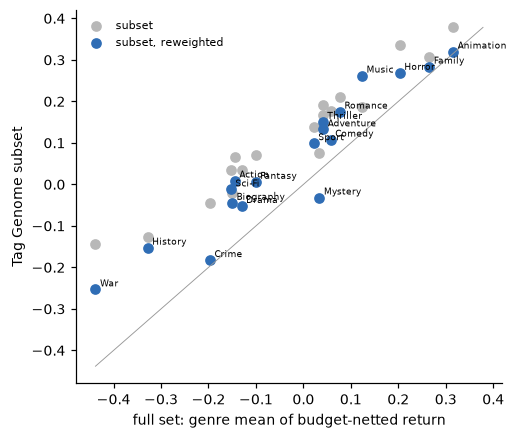

In [58]:
cv_ = pd.read_csv(FX / "coverage.csv")
print(FXS["coverage"])
fig, ax = plt.subplots(figsize=(5, 4.4))
ax.scatter(cv_["full_set"], cv_["subset"], color=GREY, label="subset")
ax.scatter(cv_["full_set"], cv_["subset_reweighted"], color=BLUE, label="subset, reweighted")
for _, r in cv_.iterrows():
    ax.annotate(r["genre"], (r["full_set"], r["subset_reweighted"]), fontsize=6, xytext=(3, 2), textcoords="offset points")
lo, hi = cv_[["full_set", "subset", "subset_reweighted"]].min().min(), cv_[["full_set", "subset", "subset_reweighted"]].max().max()
ax.plot([lo, hi], [lo, hi], color="#999", lw=.6)
ax.set_xlabel("full set: genre mean of budget-netted return")
ax.set_ylabel("Tag Genome subset")
ax.legend(fontsize=7, frameon=False)
plt.show()

**Genre mix, without the fame in it.** The effective number of genres against the budget-netted return, per
standard deviation, alone and with the log total, rating and votes held fixed; IMDb's count of genres for
comparison:

In [59]:
pd.read_csv(FX / "spread.csv")

,model,coef_per_sd,lo,hi,p
0,effective genres alone,0.129,0.090,0.169,0.000
1,+ log total,-0.157,-0.216,-0.097,0.000
2,"+ log total, rating, ln votes",-0.117,-0.174,-0.060,0.000
3,"IMDb number of genres, + rating, ln votes",-0.122,-0.157,-0.088,0.000


**Genre shares from the screenplay, known before release.** A ridge regression from each script's embedding to
its Tag Genome shares (out-of-fold for the films used in training). A script holds no ratings and no audience, so
these shares can't carry reception. First, are they a valid measure of genre?

In [60]:
pd.read_csv(FX / "script_shares_validation.csv")

,representation,films_with_script,trained_on,mean_auc_vs_imdb_labels,median_corr_with_tag_genome_share_oof,dominant_genre_in_imdb_tags
0,script_minilm,1621,1174,0.898,0.654,0.808
1,script_word2vec,1621,1174,0.896,0.625,0.805


In [61]:
print(f"{FXS['common_set_films']:,} films in the common set")
pd.read_csv(FX / "script_shares_cv_r2.csv")

1,598 films in the common set


,films,model,cv_r2,added
0,common set,IMDb tags,0.121,0.008
1,common set,script shares (MiniLM),0.115,0.002
2,common set,script shares (Word2Vec),0.117,0.004
3,common set,IMDb tags + script shares (MiniLM),0.119,0.006
4,"common set, rating and votes in base",IMDb tags,0.449,0.025
5,"common set, rating and votes in base",script shares (MiniLM),0.446,0.023
6,"common set, rating and votes in base",script shares (Word2Vec),0.448,0.025
7,"common set, rating and votes in base",IMDb tags + script shares (MiniLM),0.453,0.030
8,"common set, target rating",IMDb tags,0.189,0.179
9,"common set, target rating",script shares (MiniLM),0.127,0.117


In [62]:
ss_ = pd.read_csv(FX / "script_shares_shuffle.csv").pivot(index="genre", columns="representation", values=["excess", "p_holm"])
ss_.sort_values(("excess", "IMDb tags"), ascending=False)

excess                           p_holm  \
representation IMDb tags script shares (MiniLM) IMDb tags   
genre                                                       
War                0.278                  0.021     1.000   
Family             0.193                  0.050     1.000   
Horror             0.174                  0.039     0.437   
Adventure          0.120                  0.038     0.107   
Animation          0.120                  0.076     1.000   
Romance            0.110                  0.030     1.000   
Music              0.062                  0.047     1.000   
Sport              0.043                  0.010     1.000   
Mystery            0.034                 -0.019     1.000   
Thriller           0.028                 -0.018     1.000   
Fantasy           -0.004                  0.036     1.000   
Comedy            -0.014                 -0.002     1.000   
Sci-Fi            -0.070                 -0.008     1.000   
Drama             -0.081                 -0.029     0.022   
Action            -0.090                  0.000     0.252   
History           -0.113                 -0.048     1.000   
Biography         -0.147                 -0.063     1.000   
Crime             -0.220                 -0.066     0.004   

                                       
representation script shares (MiniLM)  
genre                                  
War                             1.000  
Family                          0.291  
Horror                          1.000  
Adventure                       0.166  
Animation                       0.291  
Romance                         1.000  
Music                           1.000  
Sport                           1.000  
Mystery                         1.000  
Thriller                        1.000  
Fantasy                         0.858  
Comedy                          1.000  
Sci-Fi                          1.000  
Drama                           0.858  
Action                          1.000  
History                         1.000  
Biography                       0.291  
Crime                           0.166

**Hand check (to be filled in by the group).** Films whose dominant share is none of their IMDb genres are where
the two sources disagree most. A random sample of them is in `analysis/genre/outputs/share_fixes/hand_check_sheet.csv`:
for each, read the film's synopsis and write in `which_is_right` whether IMDb, the Tag Genome, both or neither
names its genre better. The count below updates when the sheet is filled.

In [63]:
hc = pd.read_csv(FX / "hand_check_sheet.csv").fillna("")
print(f"{FXS['films_dominant_not_in_imdb']} films disagree; sample of {len(hc)}; labelled so far: {(hc['which_is_right'] != '').sum()}")
if (hc["which_is_right"] != "").any():
    print(hc.loc[hc["which_is_right"] != "", "which_is_right"].str.lower().value_counts())
hc[["title", "year", "imdb_genres", "tag_genome_top3"]].head(10)

562 films disagree; sample of 40; labelled so far: 0


,title,year,imdb_genres,tag_genome_top3
0,Family Plot,1976,"Comedy,Crime,Drama","Mystery 0.27, Thriller 0.24, Crime 0.15"
1,Midway,1976,"Action,Drama,History","War 0.28, History 0.24, Action 0.17"
2,Hair,1979,"Comedy,Drama,Musical","Music 0.67, Drama 0.14, War 0.07"
3,The Great Muppet Caper,1981,"Adventure,Comedy,Crime","Family 0.36, Comedy 0.22, Animation 0.14"
4,Breathless,1983,"Action,Drama,Romance","Fantasy 0.31, Thriller 0.15, Romance 0.14"
5,Valley Girl,1983,"Comedy,Romance","Music 0.47, Romance 0.39, Drama 0.04"
6,Explorers,1985,"Adventure,Comedy,Family","Sci-Fi 0.30, Adventure 0.27, Family 0.19"
7,Subway,1985,Thriller,"Romance 0.36, Action 0.29, Drama 0.15"
8,The Golden Child,1986,"Action,Adventure,Comedy","Fantasy 0.26, Action 0.20, Comedy 0.20"
9,Star Trek V: The Final Frontier,1989,"Action,Adventure,Fantasy","Sci-Fi 0.50, Adventure 0.23, Action 0.14"


## 22. Summary

Printed from the cells above, so it changes with the data.

In [64]:
up = [g for g in SEVEN if main.loc[g, "excess"] > 0]
down = [g for g in SEVEN if main.loc[g, "excess"] < 0]
v = S["sets"]["usable_money"]
print("Core:")
print(f"1. Main test ({v['films']:,} films): above their budgets: " + ", ".join(f"{g} x{np.exp(main.loc[g, 'excess']):.2f}" for g in up)
      + "; below: " + ", ".join(f"{g} x{np.exp(main.loc[g, 'excess']):.2f}" for g in down) + ".")
print(f"2. These pass with no matching, budget deciles, budget x era and ranks. Genre adds {v['r2_added_by_genre']:.3f} to R2 "
      f"on top of budget and era ({v['r2_budget_era']:.3f}).")
keep_ = all(np.sign(sm.loc[g, 'excess']) == np.sign(main.loc[g, 'excess']) and
            np.sign(tr.loc[g, 'trim_top10']) == np.sign(main.loc[g, 'excess']) for g in SEVEN)
print(f"3. Same sign with the smooth budget curve and without each genre's top 10 films, for all of them: {keep_}.")
ft = tiers[tiers["excess"].notna()]
mid = ft[ft["p_holm"] < .05]
print(f"4. Budget tiers: {len(mid)} of {len(ft)} cells pass, " + ", ".join(f"{t} {(mid['tier'] == t).sum()}" for t in names) + ".")
cs = view("in_common_set")
print("5. Common set: passes the budget shuffle: " + ", ".join(f"{g} {cs.loc[g, 'excess']:+.3f}" for g in cs.index[cs["p_holm"] < .05]) + ".")
o_ = pd.read_csv(BR / "specialists_ols.csv").set_index(["films", "term"])
t_ = pd.read_csv(BR / "typicality_ols.csv").set_index(["films", "term"])
print(f"6. Before release: a team's earlier experience in the film's genres "
      f"{o_.loc[('history: all earlier IMDb movies, sequels left out', 'genre_experience'), 'coef_per_sd']:+.3f} per SD (sequels left out; "
      f"shuffle p {BRS['specialists']['shuffle_p_genre_experience']}); script typicality "
      f"{t_.loc[('+ script-quality controls, sequels left out', 'script_typicality'), 'coef_per_sd']:+.3f} per SD with script quality held fixed "
      f"(shuffle p {BRS['typicality']['shuffle_p']}).")
gt_ = pd.read_csv(TM / "genre_tests.csv")
un_ = gt_[gt_["run"] == "union: Wikipedia, else TMDB"].set_index("genre")
print(f"7. Second source: the seven hold on TMDB genres and TMDB money; with the {TMS['money']['films_wikipedia_lacks_with_clean_tmdb_money']} films "
      f"Wikipedia lacks added back (half of them below budget), {sum(un_.loc[g, 'p_holm'] < .05 for g in SEVEN)} of the seven still pass.")
rt_ = pd.read_csv(TM / "rating_tests.csv").set_index("genre")
hs2 = pd.read_csv(TM / "horror_subgenres.csv").set_index("subgenre")
print(f"8. Rating: G {rt_.loc['G', 'excess']:+.2f}, PG {rt_.loc['PG', 'excess']:+.2f}, R {rt_.loc['R', 'excess']:+.2f}; genre order kept "
      f"(Spearman {TMS['rating']['spearman_genre_effects_with_vs_without_rating']}). Horror subgenres: supernatural "
      f"{hs2.loc['supernatural', 'excess']:+.2f}, found footage {hs2.loc['found footage', 'excess']:+.2f}, creature {hs2.loc['creature', 'excess']:+.2f}.")
wt_ = pd.read_csv(CAT / "wikidata_genre_tests.csv")
wh_ = pd.read_csv(CAT / "wikidata_horror_subgenres.csv").set_index("category")
kt_ = pd.read_csv(CAT / "keyword_category_tests.csv")
kn_ = CATS["keyword_network"]
print(f"9. Finer categories: {(wt_['p_holm'] < .05).sum()} of {len(wt_)} Wikidata genres pass; supernatural horror film "
      f"{wh_.loc['supernatural horror film', 'excess']:+.2f} against other Horror. Keyword network: {kn_['categories']} Louvain categories, "
      f"modularity {kn_['modularity']} against {kn_['rewired_modularity_mean']} rewired (p {kn_['modularity_p']}); "
      + ", ".join(f"{r['category']} {r['excess']:+.2f}" for _, r in kt_[kt_['p_holm'] < .05].sort_values('excess', ascending=False).iterrows()) + ".")
print()
print("Exploratory (weak evidence, not used for claims):")
g = SN["genre_network"]
print(f"   Genre network: {g['backbone_links']} of {g['pairs']} pairs beat the null; {g['families']} Louvain families, "
      f"modularity no stronger than a rewired network (p {g['modularity_p']}).")
print(f"   Film network: {fn['share_links_sharing_a_genre']:.0%} of shared-people links join films of a common genre "
      f"against {fn['share_null_mean']:.0%} after shuffling (a description, not a test of anything surprising).")
r = cv.set_index("model")["added_over_budget_era"]
print("   CV R2 added over budget + era: " + ", ".join(f"{k.lstrip('+ ')} {v:+.3f}" for k, v in r.items() if k != "budget + era") + ".")
fc_ = cr.set_index(["films", "model"])["added"]
print(f"   Fixed Tag Genome shares, rating and votes held fixed: {fc_[('tag_genome_films, rating and votes in base', 'shares (chosen)')]:+.3f} "
      f"against {fc_[('tag_genome_films, rating and votes in base', 'IMDb tags')]:+.3f} for the tags.")
print(f"   Horror plots: above-budget words " + ", ".join(wtop[wtop.side == 'hit']['word'].head(6))
      + "; in the scripts this does not replicate (supernatural words "
      f"{HSS['supernatural_in_script']['difference']:+.3f}, p {HSS['supernatural_in_script']['p']}).")

Core:
1. Main test (6,346 films): above their budgets: Animation x1.37, Family x1.31, Horror x1.22; below: Action x0.87, Crime x0.82, Drama x0.88, History x0.72.
2. These pass with no matching, budget deciles, budget x era and ranks. Genre adds 0.032 to R2 on top of budget and era (0.063).
3. Same sign with the smooth budget curve and without each genre's top 10 films, for all of them: True.


4. Budget tiers: 10 of 59 cells pass, under $5M 0, $5-30M 6, $30-100M 3, $100M+ 1.
5. Common set: passes the budget shuffle: Adventure +0.132, Crime -0.200, Drama -0.087.
6. Before release: a team's earlier experience in the film's genres +0.070 per SD (sequels left out; shuffle p 0.001); script typicality +0.101 per SD with script quality held fixed (shuffle p 0.001).
7. Second source: the seven hold on TMDB genres and TMDB money; with the 677 films Wikipedia lacks added back (half of them below budget), 6 of the seven still pass.
8. Rating: G +0.56, PG +0.35, R -0.10; genre order kept (Spearman 0.977). Horror subgenres: supernatural +0.60, found footage +1.48, creature -0.32.
9. Finer categories: 22 of 112 Wikidata genres pass; supernatural horror film +0.74 against other Horror. Keyword network: 13 Louvain categories, modularity 0.663 against 0.4993 rewired (p 0.0196); 4: halloween +0.35, 9: villain +0.19, 2: action hero -0.13, 6: dystopia -0.18, 10: drugs -0.22.

Exploratory (weak 